# Практическая работа № 1. Открытые API, парсинг HTML (BeautifulSoup, XPath) и регулярные выражения

**Дисциплина:** «Анализ больших данных и рыночных тенденций»  
**Направление:** 38.04.05 «Бизнес-информатика», магистратура  
**Формат:** интерактивный ноутбук Google Colab · до 100 баллов · срок сдачи — по графику курса

## Цель работы

Научиться самостоятельно добывать рыночные данные там, где нет готового датасета: забирать их из открытых API, извлекать из HTML-страниц, приводить «грязный» текст к числам и датам и превращать результат в управленческие выводы.

## Задачи

1. Спроектировать вежливый сбор данных через REST API: параметры, пагинация, заголовки, паузы, повторные попытки, обработка ошибок.
2. Извлечь данные из статических HTML-страниц двумя независимыми способами — CSS-селекторами BeautifulSoup и выражениями XPath — и сверить результаты.
3. Нормализовать «грязные» поля (цены, остатки, зарплатные вилки, даты, технологии в тексте требований) регулярными выражениями.
4. Собрать единый `pandas.DataFrame`, провести разведочный анализ и построить корректные графики.
5. Сформулировать выводы и рекомендации для лица, принимающего решение, с опорой на посчитанные метрики.

## Стек

| Слой | Инструменты |
|---|---|
| Сбор | `requests` (+ `urllib3.Retry`), открытые REST API, кэш ответов на диске |
| Разбор HTML | `BeautifulSoup4` (CSS-селекторы), `lxml` (XPath) |
| Очистка | `re` — регулярные выражения |
| Анализ и графики | `pandas`, `numpy`, `matplotlib`, `seaborn` |
| Среда | Google Colab (работает и в локальном Jupyter) |

## Что сдаётся

Выполненный ноутбук **со всеми выводами ячеек**, загруженный в личный публичный репозиторий GitHub; в LMS сдаётся **ссылка на репозиторий**. Файлы и архивы не принимаются. Ключи, токены и пароли в ноутбуке недопустимы — за это снимаются баллы (см. раздел «Штрафы»).

---

**Вариант 2** · E-commerce · «Ценовое позиционирование в нише деловой литературы»
**Выполнил(а):** Циприков Денис Михайлович, БД-251м
**Дата сбора данных:** 16.10.2026, 22:00 МСК

| Блок | Источник | Параметры варианта | Что сделано сверх шаблона |
|---|---|---|---|
| API | opendata.trudvsem.ru («Работа в России») | `text="аналитик маркетплейсов"`, 4 стр. × 100 | расширяющий запрос «маркетплейс», роли по RegEx, обезличивание работодателя |
| Сайт | books.toscrape.com | `category="business_35"`, 3 стр. | бенчмарк-категория Nonfiction, остатки со страниц товаров через XPath |
| Этика и надёжность | оба источника | — | проверка `robots.txt` и условий (шаг 1.3), журнал запросов (шаг 3.5), аварийные режимы |
| ★ | — | — | задание C: дедупликация вакансий (шинглы + Жаккар) |

## Как работать с этим ноутбуком

1. **Файл → Сохранить копию на Диске.** Работайте только в своей копии.
2. В ячейке «Шаг 1» задайте **номер варианта** (выдаёт преподаватель), свой контактный e-mail и паузу между запросами. Параметры варианта подставятся автоматически.
3. Выполняйте ячейки **строго сверху вниз**. Перед каждым блоком кода есть пояснение «Зачем мы это делаем», после — «Как читать полученный вывод».
4. Места, которые нужно дописать, помечены `TODO`. Пока шаг не выполнен, ячейка честно падает с `NotImplementedError` — это нормально.
5. Перед сдачей запустите ячейку **самопроверки**: она должна показать «Выполнено: 11 из 11».

### Три правила вежливого сбора данных

* **Пауза между запросами.** `REQUEST_PAUSE = 0.5` секунды — нижняя граница для учебной работы. Сервер, который вы «положите», принадлежит другим людям.
* **Кэш включён по умолчанию.** Повторный запуск ячейки берёт ответ с диска, а не из сети: это и быстрее, и вежливее. Чтобы получить свежие данные, выключите `USE_CACHE` или очистите папку кэша.
* **Никаких ключей в коде.** Токены читаются функцией `get_secret()` из Colab Secrets (значок ключа слева) или переменных окружения.

### Если источник недоступен

Интернет в Colab иногда блокирует отдельные домены, а сайты меняют вёрстку. В ноутбуке предусмотрены аварийные режимы (синтетические данные и офлайн-снимок разметки): пайплайн доработает до конца, но в выводе появится предупреждение. **Выводы по аварийным данным не принимаются** — повторите сбор, когда источник снова доступен.

## Мини-теория 1. REST API: как устроен этичный сбор

**API** — это контракт: вы отправляете HTTP-запрос по определённому адресу и получаете структурированный ответ (почти всегда JSON). В отличие от парсинга HTML, здесь данные уже разобраны по полям, а правила использования описаны явно.

### Анатомия запроса

```
GET https://api.github.com/search/repositories ? q=web+scraping & sort=stars & per_page=50 & page=2
    └──────── эндпоинт ────────────────────────┘ └──────────── параметры запроса ───────────────┘
Заголовки: User-Agent: MGPU-BI-PW1/1.0 (contact: student@mgpu.ru)
           Authorization: Bearer <токен>        ← если сервис требует авторизацию
```

* **Эндпоинт** — «ручка» сервиса: `/vacancies`, `/works`, `/search/repositories`.
* **Параметры** уточняют выборку: поисковая строка, фильтры, сортировка, размер страницы.
* **Заголовки** описывают клиента. `User-Agent` с контактом — правило хорошего тона: по нему администратор сервиса сможет с вами связаться, а не просто заблокировать.
* **Коды ответа** — первое, что нужно проверять:

| Код | Что значит | Что делать |
|---|---|---|
| 200 | всё хорошо | разбирать `r.json()` |
| 301 / 302 | адрес изменился | проверить итоговый `r.url` |
| 400 | неверные параметры | сверить имена и типы параметров с документацией |
| 401 / 403 | нет доступа или ключа | получить ключ, проверить заголовки; иногда сервис закрыл публичный доступ |
| 404 | объекта нет | проверить путь и идентификатор |
| 429 | превышен лимит | подождать `Retry-After`, увеличить паузу |
| 5xx | сбой на стороне сервиса | повторить с экспоненциальной задержкой |

### Пагинация

Сервисы отдают данные страницами. Три частых схемы:

| Схема | Параметры | Примеры |
|---|---|---|
| Номер страницы | `page`, `per_page` | GitHub, OpenAlex |
| Смещение и размер | `offset`, `limit` | «Работа в России» |
| Курсор | `cursor`, `next` | сервисы с большим объёмом |

Правило остановки: страница вернула меньше записей, чем `per_page`, — данные закончились. Бесконечный `while True` без такой проверки — классическая ошибка, которая либо зациклится, либо упрётся в лимит.

### Ограничение частоты (rate limiting)

Сервис считает ваши запросы и при превышении отвечает 429. Практика:

* пауза между запросами (`time.sleep`);
* повторные попытки с **экспоненциальной задержкой** — в работе это `urllib3.Retry(backoff_factor=1.5)`: 1,5 с → 3 с → 6 с;
* уважение заголовков `X-RateLimit-Remaining` и `Retry-After`;
* кэширование ответов, чтобы при отладке не ходить в сеть повторно.

### Ключи и секреты

Многие API требуют ключ. Хранить его в коде нельзя: ноутбук уедет в репозиторий вместе с ключом, и ключ придётся отзывать. В Colab есть **Secrets** (значок ключа на панели слева): значение хранится в аккаунте, а код получает его через `userdata.get("MY_KEY")`. В работе это обёрнуто в `get_secret()`.

### Что изменилось к 2026 году (важно для выбора источника)

* **hh.ru**: с апреля 2026 публичный метод `GET /vacancies` отвечает `403 Forbidden` на неавторизованные запросы; ключ выдают в основном работодателям и рекрутинговым сервисам через модерацию приложения. Старые учебные примеры с hh.ru больше не воспроизводятся. Российская открытая альтернатива — портал **«Работа в России»** (`opendata.trudvsem.ru`), данные Роструда, ключ не нужен.
* **OpenAlex**: с 13 февраля 2026 всем запросам нужен бесплатный `api_key`, параметр `mailto` и «polite pool» отменены. Действует бесплатный лимит около $1 в сутки; запросы `search` дороже, чем `filter`, а получение объекта по идентификатору бесплатно. Отсюда практический приём: `per-page=100` и фильтры вместо поиска.
* **GitHub**: без токена — 60 запросов в час на IP, с персональным токеном — 5000 в час; у поиска отдельный лимит (10 и 30 запросов в минуту соответственно).

Вывод для аналитика: **источник — это не константа**. Перед сбором проверяйте документацию и код ответа, а в отчёте фиксируйте дату сбора.

## Мини-теория 2. HTML, DOM и селекторы: BeautifulSoup против XPath

Когда API нет, данные забирают из HTML. Браузер превращает разметку в **DOM** — дерево элементов:

```
html
└── body
    └── article.product_pod                 ← карточка товара
        ├── h3 > a[title="Sharp Objects"]   ← название лежит в АТРИБУТЕ, а не в тексте
        ├── p.star-rating.Three             ← рейтинг закодирован КЛАССОМ
        └── div.product_price
            ├── p.price_color   → "£47.82"
            └── p.instock.availability → "In stock (22 available)"
```

Задача парсера — описать путь к нужному узлу так, чтобы он пережил мелкие изменения вёрстки.

### Два инструмента

| | BeautifulSoup + CSS | lxml + XPath |
|---|---|---|
| Синтаксис | `soup.select("article.product_pod p.price_color")` | `tree.xpath('//article[contains(@class,"product_pod")]//p[@class="price_color"]/text()')` |
| Читаемость | выше, привычно по вёрстке | ниже, но выражения мощнее |
| Атрибут | `el.get("title")` | `.../@title` |
| Текст | `el.get_text(" ", strip=True)` | `.../text()` |
| Поиск по тексту | `soup.find("th", string="UPC")` | `//th[text()="UPC"]` |
| Движение «вверх» и «вбок» | `el.parent`, `el.find_next_sibling()` | оси: `parent::`, `following-sibling::`, `ancestor::` |
| Условие по числу | средствами Python | `[position() <= 3]`, `[last()]` |
| Скорость | ниже (чистый Python поверх парсера) | выше (C-библиотека) |

**Когда что удобнее.** CSS-селекторы — для «плоских» повторяющихся карточек. XPath — когда нужно зацепиться за текст-подпись и взять соседнюю ячейку: классика — таблица характеристик товара:

```python
# «Найти ячейку th со словом UPC и взять следующий за ней td»
tree.xpath('//th[text()="UPC"]/following-sibling::td[1]/text()')
```

### Практические правила

1. **Цепляйтесь за смысл, а не за форму.** `div > div > div:nth-child(3)` сломается при первом же редизайне; `p.price_color` переживёт его.
2. **Проверяйте на нескольких страницах.** Первая страница часто не показательна: где-то нет скидки, где-то нет рейтинга.
3. **Отсутствие элемента — норма.** `select_one()` вернёт `None`; парсер должен записать `None` в поле, а не падать.
4. **Сверяйте два способа.** В этой работе один и тот же набор разбирается BS4 и XPath: расхождение — сигнал об ошибке в селекторе.
5. **Динамические сайты.** Если данные подгружаются JavaScript, в HTML их нет. Тогда ищут тот же запрос в панели «Сеть» браузера и обращаются к нему напрямую — это снова API.

## Мини-теория 3. Регулярные выражения для «грязных» данных

Из API и HTML приходят строки, а бизнес-метрики считаются по числам и датам. Регулярные выражения — самый короткий путь от `"от 60 000 до 90 000 руб."` к паре `(60000, 90000)`.

### Рабочий минимум синтаксиса

| Конструкция | Значение | Пример |
|---|---|---|
| `\d`, `\w`, `\s` | цифра, буква/цифра/подчёркивание, пробельный символ | `\d{4}` — год |
| `+`, `*`, `?`, `{n,m}` | повторения | `\d{1,3}` |
| `(?P<name>...)` | именованная группа | `(?P<min>\d+)` → `m.group("min")` |
| `(?:...)` | группировка без захвата | `(?:руб\.?|₽)` |
| `[...]`, `[^...]` | символьный класс и его отрицание | `[£$€₽]` |
| `\b` | граница слова | `\bBI\b` не совпадёт внутри `BigData` |
| `?` после квантификатора | ленивый режим | `<.+?>` |
| `re.I`, `re.S`, `re.X` | флаги: регистр, `.` включая перевод строки, «читаемый» режим | |

Функции: `re.search` — первое совпадение, `re.findall` — все, `re.sub` — замена, `re.compile` — скомпилировать один раз и переиспользовать.

### Шаблоны, которые понадобятся в работе

| Задача | Выражение | Тонкость |
|---|---|---|
| Цена | `(?P<num>\d{1,3}(?:[\s\u00a0]\d{3})*(?:[.,]\d{1,2})?)` | в `1 250,50 ₽` стоит **неразрывный** пробел `\u00a0`, а десятичный разделитель — запятая |
| Остаток | `\((?P<n>\d+)\s*available\)` | «Out of stock» — это ноль, а не пропуск |
| Зарплатная вилка | `(?:от\s*(?P<min>\d[\d\s]*))?\s*(?:до\s*(?P<max>\d[\d\s]*))?` | «по договорённости» → `(None, None)`; одиночное число — это и нижняя, и верхняя граница |
| Дата | `(?P<d>\d{2})[.\-/](?P<m>\d{2})[.\-/](?P<y>\d{4})` и `\d{4}-\d{2}-\d{2}` | в одном источнике встречаются оба формата |
| Технология в тексте | `(?<![\w])(python|sql|power bi)(?![\w])` | без границ `bi` найдётся в «combined» |

### Чего делать не нужно

* **Разбирать HTML регулярками.** Для разметки есть парсер дерева; регулярное выражение сломается на вложенности и незакрытых тегах. Регулярки применяются к уже извлечённому тексту.
* **Писать одно «универсальное» выражение на все случаи.** Проще и надёжнее несколько маленьких функций с тестами.
* **Верить, что очистка прошла успешно.** Всегда считайте долю распознанных значений: если цена распозналась в 62 % строк, дальше вы анализируете смещённую выборку.

В работе каждая функция очистки сопровождается набором тестов вида «вход → ожидаемый выход». Это дешёвая страховка: при изменении формата данных тест падает сразу, а не через три графика.

## Право и этика сбора данных

Аналитик отвечает не только за качество данных, но и за законность их получения.

* **`robots.txt` и пользовательское соглашение.** Перед сбором смотрим `https://сайт/robots.txt` и раздел об использовании данных. Запрет в `robots.txt` — не «рекомендация для поисковиков», а явно выраженная воля владельца ресурса.
* **Нагрузка.** Массовые запросы без пауз — это фактически мини-DDoS. Пауза, кэш и ограничение глубины пагинации обязательны.
* **Персональные данные.** Имена, контакты, резюме — персональные данные (152-ФЗ). В учебной работе они не собираются и не публикуются; в репозиторий выкладываются только агрегаты и обезличенные поля.
* **Авторские права и лицензии.** Тексты и изображения защищены авторским правом; открытые данные публикуются под лицензией, которую нужно указать в отчёте.
* **Прозрачность.** В `User-Agent` указывается назначение и контакт. Маскировка под браузер, обход капчи и ротация прокси в учебной работе не используются.

Поэтому в работе намеренно выбраны **учебные витрины** (`books.toscrape.com`, `quotes.toscrape.com`, `webscraper.io/test-sites`, `scrapethissite.com`), созданные специально для тренировки, и **открытые государственные и научные данные**. Навык переносится на коммерческие источники, а юридические риски — нет.

### Шаг 1. Окружение, параметры варианта и работа с ключами

**Зачем мы это делаем.** Прежде чем отправить первый запрос, нужно подготовить инфраструктуру сбора: клиент с повторными попытками, паузами и кэшем, единый `User-Agent` с контактом и безопасный способ получить ключ. Это тот код, который в реальном проекте пишется один раз и переиспользуется во всех сборах.

Обратите внимание на три детали:

* `Retry(backoff_factor=1.5, status_forcelist=(429, 500, 502, 503, 504))` — автоматические повторы с нарастающей паузой только для тех кодов, где повтор имеет смысл;
* `polite_get()` никогда не выбрасывает исключение: она возвращает пару «данные, метаинформация», и ошибка становится обычной веткой логики, а не аварией всего ноутбука;
* `get_secret()` ищет ключ в Colab Secrets, затем в переменных окружения и только потом спрашивает его с клавиатуры.

In [3]:
#@title Шаг 1. Окружение, параметры варианта и безопасная работа с ключами { display-mode: "form" }
VARIANT = 2               #@param {type:"slider", min:1, max:30, step:1}
CONTACT_EMAIL = "ciprikovd@mail.ru"  #@param {type:"string"}
USE_CACHE = True          #@param {type:"boolean"}
REQUEST_PAUSE = 0.5       #@param {type:"slider", min:0.1, max:3, step:0.1}

import importlib, io, json, math, os, random, re, subprocess, sys, textwrap, time, hashlib, warnings
from datetime import datetime, timedelta, timezone
from pathlib import Path
from collections import Counter

def ensure(pkg, module=None):
    """Ставим пакет только если его нет: в Colab почти всё уже предустановлено."""
    try:
        importlib.import_module(module or pkg)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=False)
        importlib.invalidate_caches()

for pkg, mod in [("requests", "requests"), ("beautifulsoup4", "bs4"), ("lxml", "lxml"),
                 ("pandas", "pandas"), ("matplotlib", "matplotlib"), ("seaborn", "seaborn")]:
    ensure(pkg, mod)

import requests
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry
from bs4 import BeautifulSoup
from lxml import html as lxml_html, etree as lxml_etree
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 160, "display.max_columns", 40)

# --- вежливый HTTP-клиент: User-Agent с контактом, ретраи, экспоненциальная пауза --------
# Заголовки HTTP передаются в latin-1, поэтому User-Agent пишем только латиницей.
USER_AGENT = f"MGPU-BI-PW1/1.0 (educational project; contact: {CONTACT_EMAIL})"

def make_session(total=4, backoff=1.5):
    s = requests.Session()
    retry = Retry(total=total, backoff_factor=backoff,
                  status_forcelist=(408, 429, 500, 502, 503, 504),
                  allowed_methods=frozenset(["GET"]),
                  respect_retry_after_header=True)
    adapter = HTTPAdapter(max_retries=retry, pool_maxsize=8)
    s.mount("https://", adapter)
    s.mount("http://", adapter)
    s.headers.update({"User-Agent": USER_AGENT, "Accept-Encoding": "gzip, deflate"})
    return s

SESSION = make_session()
CACHE_DIR = Path("/content/pw1_cache" if Path("/content").exists() else "pw1_cache")
CACHE_DIR.mkdir(parents=True, exist_ok=True)
REQUEST_LOG = []

def polite_get(url, params=None, headers=None, expect="json", timeout=25,
               pause=None, use_cache=None):
    """Один GET-запрос: кэш → сеть → пауза. Возвращает (data, meta); исключения не выбрасываются.

    meta содержит статус, время ответа, признак кэша и остаток лимита, если сервер его сообщил.
    """
    pause = REQUEST_PAUSE if pause is None else pause
    use_cache = USE_CACHE if use_cache is None else use_cache
    key = hashlib.sha1(f"{url}|{json.dumps(params, sort_keys=True, ensure_ascii=False, default=str)}"
                       .encode("utf-8")).hexdigest()[:16]
    cached = CACHE_DIR / f"{key}.{'json' if expect == 'json' else 'txt'}"
    if use_cache and cached.exists():
        raw = cached.read_text(encoding="utf-8")
        meta = {"url": url, "status": 200, "from_cache": True, "error": None}
        REQUEST_LOG.append(meta)
        return (json.loads(raw) if expect == "json" else raw), meta

    meta = {"url": url, "status": None, "from_cache": False, "error": None}
    try:
        r = SESSION.get(url, params=params, headers=headers, timeout=timeout)
    except (requests.RequestException, UnicodeError) as e:   # сеть, таймаут, DNS, битый заголовок
        meta["error"] = f"{type(e).__name__}: {e}"
        REQUEST_LOG.append(meta)
        return None, meta

    meta.update(status=r.status_code, elapsed_s=round(r.elapsed.total_seconds(), 2),
                limit_remaining=r.headers.get("X-RateLimit-Remaining"))
    if r.status_code == 429:
        meta["error"] = "429 Too Many Requests: превышен лимит, увеличьте паузу"
    elif r.status_code != 200:
        meta["error"] = f"HTTP {r.status_code}: {r.text[:180]}"
    REQUEST_LOG.append(meta)
    if meta["error"]:
        return None, meta

    time.sleep(pause)                                  # вежливость: не «долбим» сервер
    if expect == "json":
        try:
            data = r.json()
        except ValueError as e:
            meta["error"] = f"ответ не JSON: {e}"
            return None, meta
        cached.write_text(json.dumps(data, ensure_ascii=False), encoding="utf-8")
    else:
        # Доработка: books.toscrape.com не сообщает charset в Content-Type, и requests
        # декодирует страницу как latin-1 («£» превращается в «Â£»). Берём UTF-8.
        if "charset" not in r.headers.get("Content-Type", "").lower():
            r.encoding = "utf-8"
        data = r.text
        cached.write_text(data, encoding="utf-8")
    return data, meta

def todo(step):
    raise NotImplementedError(f"Не выполнен шаг TODO {step} — допишите код в отмеченном месте")

def get_secret(name, hint=""):
    """Ключи берём из Colab Secrets → переменных окружения → ввода с клавиатуры.
    Хардкодить ключ в ячейке нельзя: ноутбук уедет в Git вместе с ним."""
    try:
        from google.colab import userdata
        value = userdata.get(name)
        if value:
            return value
    except Exception:
        pass
    if os.environ.get(name):
        return os.environ[name]
    try:
        import getpass
        return getpass.getpass(f"{name} {hint}: ").strip() or None
    except Exception:
        return None

import bs4
print(f"Python {sys.version.split()[0]} | requests {requests.__version__} | bs4 {bs4.__version__} | "
      f"lxml {lxml_etree.__version__} | pandas {pd.__version__} | seaborn {sns.__version__}")
print(f"Вариант: {VARIANT} | кэш: {CACHE_DIR} | пауза между запросами: {REQUEST_PAUSE} с")

Python 3.13.16 | requests 2.32.4 | bs4 4.13.5 | lxml 6.1.3 | pandas 2.2.3 | seaborn 0.13.2
Вариант: 2 | кэш: /content/pw1_cache | пауза между запросами: 0.5 с


**Как читать вывод.** В строке версий проверьте, что все библиотеки импортировались: в Colab они предустановлены, установка запускается только при отсутствии. Путь кэша пригодится, если понадобится принудительно обновить данные — достаточно удалить папку. Если пауза меньше 0,5 с, увеличьте её: при сборе десятков страниц это разница между «данные собраны» и «IP временно заблокирован».

In [4]:
#@title Шаг 1.1. Параметры моего варианта { display-mode: "form" }
VARIANTS = [
{
"id": 1,
"area": "HR-аналитика",
"task": "Рынок труда AI/ML-инженеров: где искать кадры и сколько они стоят",
"api": "trudvsem",
"api_params": {
"text": "инженер машинного обучения",
"pages": 5,
"per_page": 100
},
"site": "books",
"site_params": {
"category": "science_22",
"pages": 3
},
"metrics": "Медиана и IQR зарплатной вилки по регионам; топ-10 работодателей; доля вакансий с удалённой работой; гистограмма цен каталога"
},
{
"id": 2,
"area": "E-commerce",
"task": "Ценовое позиционирование в нише деловой литературы",
"api": "trudvsem",
"api_params": {
"text": "аналитик маркетплейсов",
"pages": 4,
"per_page": 100
},
"site": "books",
"site_params": {
"category": "business_35",
"pages": 3
},
"metrics": "Распределение цен, медиана по рейтингу, доля товаров в наличии, boxplot зарплат"
},
{
"id": 3,
"area": "Финтех",
"task": "Валютный риск закупок: динамика USD и EUR за квартал",
"api": "cbr",
"api_params": {
"currencies": [
"USD",
"EUR"
],
"days": 90
},
"site": "books",
"site_params": {
"category": "travel_2",
"pages": 2
},
"metrics": "Линейный график курсов, дневная волатильность (std доходностей), пересчёт цен каталога в рубли"
},
{
"id": 4,
"area": "Мониторинг конкурентов",
"task": "Сравнение ассортимента двух товарных категорий",
"api": "github",
"api_params": {
"q": "price monitoring",
"sort": "stars",
"pages": 2,
"per_page": 50
},
"site": "books",
"site_params": {
"category": "fiction_10",
"pages": 4
},
"metrics": "Boxplot цен по категориям, топ-10 репозиториев по звёздам, scatter «звёзды — форки»"
},
{
"id": 5,
"area": "Наука и инновации",
"task": "Научная активность в сфере FinTech: динамика публикаций",
"api": "openalex",
"api_params": {
"search": "fintech",
"from_year": 2019,
"per_page": 100,
"pages": 2
},
"site": "quotes",
"site_params": {
"tag": "inspirational",
"pages": 4
},
"metrics": "Публикации по годам, топ-10 организаций, доля open access, частотный анализ тегов"
},
{
"id": 6,
"area": "Логистика",
"task": "Погодные риски на складских хабах: планирование окон отгрузки",
"api": "openmeteo",
"api_params": {
"cities": [
"Москва",
"Екатеринбург",
"Новосибирск"
],
"days": 14
},
"site": "books",
"site_params": {
"category": "history_32",
"pages": 2
},
"metrics": "Температура и осадки по хабам, число «рисковых» дней, медиана цен каталога"
},
{
"id": 7,
"area": "HR-аналитика",
"task": "Спрос на дата-инженеров и требования к стеку",
"api": "trudvsem",
"api_params": {
"text": "инженер данных",
"pages": 5,
"per_page": 100
},
"site": "quotes",
"site_params": {
"tag": "life",
"pages": 3
},
"metrics": "Топ-15 технологий в требованиях (RegEx), медиана зарплат по опыту, облако тегов цитат"
},
{
"id": 8,
"area": "E-commerce",
"task": "Влияние рейтинга на цену: есть ли премия за качество",
"api": "github",
"api_params": {
"q": "recommender system",
"sort": "stars",
"pages": 2,
"per_page": 50
},
"site": "books",
"site_params": {
"category": "romance_8",
"pages": 4
},
"metrics": "Scatter «рейтинг — цена» с линией тренда, ANOVA-подобное сравнение медиан, топ репозиториев"
},
{
"id": 9,
"area": "Финтех",
"task": "Стоимость валютной корзины импортёра",
"api": "cbr",
"api_params": {
"currencies": [
"USD",
"EUR",
"CNY"
],
"days": 120
},
"site": "webscraper",
"site_params": {
"section": "computers/laptops",
"pages": 3
},
"metrics": "Индекс корзины (веса 0.5/0.3/0.2), максимальная просадка, цены ноутбуков в рублях по курсу"
},
{
"id": 10,
"area": "Мониторинг конкурентов",
"task": "Глубина ассортимента и «дыры» в наличии у конкурента",
"api": "trudvsem",
"api_params": {
"text": "категорийный менеджер",
"pages": 4,
"per_page": 100
},
"site": "books",
"site_params": {
"category": "mystery_3",
"pages": 4
},
"metrics": "Доля out-of-stock, распределение остатков (RegEx из «In stock (N available)»), топ регионов по вакансиям"
},
{
"id": 11,
"area": "Наука и инновации",
"task": "Публикационный ландшафт по теме «supply chain analytics»",
"api": "openalex",
"api_params": {
"search": "supply chain analytics",
"from_year": 2020,
"per_page": 100,
"pages": 2
},
"site": "scrapethissite",
"site_params": {
"section": "countries",
"pages": 1
},
"metrics": "Динамика публикаций, топ стран и организаций, связь числа публикаций с населением стран"
},
{
"id": 12,
"area": "Логистика",
"task": "Температурный режим перевозок: risk-календарь на две недели",
"api": "openmeteo",
"api_params": {
"cities": [
"Санкт-Петербург",
"Казань",
"Краснодар"
],
"days": 14
},
"site": "webscraper",
"site_params": {
"section": "computers/tablets",
"pages": 3
},
"metrics": "Heatmap «город — день», доля дней с t < 0 °C, медианы цен планшетов"
},
{
"id": 13,
"area": "HR-аналитика",
"task": "BI-аналитики: сколько стоит и что требуют работодатели",
"api": "trudvsem",
"api_params": {
"text": "BI аналитик",
"pages": 5,
"per_page": 100
},
"site": "books",
"site_params": {
"category": "business_35",
"pages": 3
},
"metrics": "Топ навыков (Power BI, SQL, Python, 1С), медиана вилки, распределение по типам занятости"
},
{
"id": 14,
"area": "Технологические тренды",
"task": "Экосистема инструментов парсинга: кто лидирует",
"api": "github",
"api_params": {
"q": "web scraping",
"sort": "stars",
"pages": 2,
"per_page": 50
},
"site": "quotes",
"site_params": {
"tag": "books",
"pages": 3
},
"metrics": "Топ-15 репозиториев, распределение по языкам, возраст проекта vs звёзды"
},
{
"id": 15,
"area": "E-commerce",
"task": "Ценовые сегменты в детской нише: где «дыра» в предложении",
"api": "trudvsem",
"api_params": {
"text": "менеджер интернет-магазина",
"pages": 4,
"per_page": 100
},
"site": "books",
"site_params": {
"category": "childrens_11",
"pages": 4
},
"metrics": "Гистограмма цен с квантилями, разбиение на сегменты (low/mid/high), топ работодателей"
},
{
"id": 16,
"area": "Финтех",
"task": "Курс юаня и импорт электроники: чувствительность цены",
"api": "cbr",
"api_params": {
"currencies": [
"CNY"
],
"days": 180
},
"site": "webscraper",
"site_params": {
"section": "phones/touch",
"pages": 2
},
"metrics": "Динамика CNY, скользящее среднее 7 дней, пересчёт цен телефонов при ±10 % курса"
},
{
"id": 17,
"area": "Наука и инновации",
"task": "Исследования по «digital twin» в промышленности",
"api": "openalex",
"api_params": {
"search": "digital twin manufacturing",
"from_year": 2018,
"per_page": 100,
"pages": 2
},
"site": "books",
"site_params": {
"category": "science_22",
"pages": 3
},
"metrics": "Динамика по годам, топ-10 авторов, доля OA, медиана цитируемости"
},
{
"id": 18,
"area": "Мониторинг конкурентов",
"task": "Сравнение цен и «звёздности» ассортимента двух категорий",
"api": "github",
"api_params": {
"q": "e-commerce analytics",
"sort": "stars",
"pages": 2,
"per_page": 50
},
"site": "books",
"site_params": {
"category": "food-and-drink_33",
"pages": 3
},
"metrics": "Две категории на одном boxplot, доля 4–5★, топ open-source решений для e-com аналитики"
},
{
"id": 19,
"area": "HR-аналитика",
"task": "Логистические профессии: дефицит кадров по регионам",
"api": "trudvsem",
"api_params": {
"text": "логист",
"pages": 6,
"per_page": 100
},
"site": "scrapethissite",
"site_params": {
"section": "countries",
"pages": 1
},
"metrics": "Топ-15 регионов по числу вакансий, медиана зарплат, связь с площадью/населением стран (демо-джойн)"
},
{
"id": 20,
"area": "Логистика",
"task": "Окна доставки в северных хабах на горизонте 16 дней",
"api": "openmeteo",
"api_params": {
"cities": [
"Мурманск",
"Архангельск",
"Якутск"
],
"days": 16
},
"site": "books",
"site_params": {
"category": "travel_2",
"pages": 2
},
"metrics": "Линии температур, число дней с осадками, стоимость «северной надбавки» как гипотеза"
},
{
"id": 21,
"area": "E-commerce",
"task": "Автоматизация мониторинга: как часто меняется наличие товара",
"api": "github",
"api_params": {
"q": "price tracker",
"sort": "stars",
"pages": 2,
"per_page": 50
},
"site": "books",
"site_params": {
"category": "sequential-art_5",
"pages": 4
},
"metrics": "Распределение остатков, доля дефицитных позиций, топ инструментов трекинга цен"
},
{
"id": 22,
"area": "Финтех",
"task": "Волатильность рубля как фактор ценообразования",
"api": "cbr",
"api_params": {
"currencies": [
"USD",
"EUR"
],
"days": 365
},
"site": "books",
"site_params": {
"category": "business_35",
"pages": 3
},
"metrics": "Годовая динамика, скользящая волатильность 30 дней, сценарии наценки 5/10/15 %"
},
{
"id": 23,
"area": "HR-аналитика",
"task": "Продуктовые аналитики: требования и вилки",
"api": "trudvsem",
"api_params": {
"text": "продуктовый аналитик",
"pages": 5,
"per_page": 100
},
"site": "quotes",
"site_params": {
"tag": "humor",
"pages": 3
},
"metrics": "Топ навыков, медиана вилки по опыту, доля вакансий без указания зарплаты"
},
{
"id": 24,
"area": "Технологические тренды",
"task": "Инструменты работы с данными: Python-экосистема",
"api": "github",
"api_params": {
"q": "pandas alternative dataframe",
"sort": "stars",
"pages": 2,
"per_page": 50
},
"site": "webscraper",
"site_params": {
"section": "computers/laptops",
"pages": 3
},
"metrics": "Топ-15 по звёздам, динамика последних обновлений, цена ноутбуков vs объём памяти (RegEx)"
},
{
"id": 25,
"area": "Наука и инновации",
"task": "Публикации по «marketplace pricing»: кто задаёт повестку",
"api": "openalex",
"api_params": {
"search": "marketplace pricing",
"from_year": 2019,
"per_page": 100,
"pages": 2
},
"site": "books",
"site_params": {
"category": "business_35",
"pages": 3
},
"metrics": "Динамика, топ организаций, распределение цитируемости (log-scale), медиана цен каталога"
},
{
"id": 26,
"area": "Логистика",
"task": "Планирование складских смен по погодным окнам",
"api": "openmeteo",
"api_params": {
"cities": [
"Ростов-на-Дону",
"Самара",
"Пермь"
],
"days": 14
},
"site": "scrapethissite",
"site_params": {
"section": "hockey",
"pages": 2
},
"metrics": "Доля благоприятных дней по хабам, heatmap, парсинг таблицы с пагинацией"
},
{
"id": 27,
"area": "Мониторинг конкурентов",
"task": "Бенчмарк цен на технику: разброс внутри линейки",
"api": "trudvsem",
"api_params": {
"text": "менеджер по закупкам",
"pages": 4,
"per_page": 100
},
"site": "webscraper",
"site_params": {
"section": "computers/laptops",
"pages": 3
},
"metrics": "Boxplot цен по брендам (RegEx из названия), коэффициент вариации, медиана зарплат закупщиков"
},
{
"id": 28,
"area": "E-commerce",
"task": "Влияние глубины каталога на средний чек (гипотеза)",
"api": "github",
"api_params": {
"q": "shopping cart analytics",
"sort": "stars",
"pages": 2,
"per_page": 50
},
"site": "books",
"site_params": {
"category": "poetry_23",
"pages": 4
},
"metrics": "Средняя цена по страницам пагинации, кумулятивная кривая ассортимента, топ репозиториев"
},
{
"id": 29,
"area": "Финтех",
"task": "Кросс-курсы и арбитраж: USD, EUR, CNY за полгода",
"api": "cbr",
"api_params": {
"currencies": [
"USD",
"EUR",
"CNY"
],
"days": 180
},
"site": "quotes",
"site_params": {
"tag": "life",
"pages": 3
},
"metrics": "Кросс-курсы EUR/USD и CNY/USD, корреляционная матрица, частотный анализ авторов цитат"
},
{
"id": 30,
"area": "E-commerce + HR (эталон преподавателя)",
"task": "Оценка ниши деловой литературы: ассортимент и цены конкурента плюс доступность кадров для запуска направления",
"api": "trudvsem",
"api_params": {
"text": "аналитик данных",
"pages": 3,
"per_page": 100
},
"site": "books",
"site_params": {
"category": "business_35",
"pages": 3
},
"metrics": "Медиана и квартили цен, цены по рейтингу, доля в наличии, зарплатная вилка по регионам, топ навыков"
}
]

API_TITLES = {
"trudvsem": "opendata.trudvsem.ru — «Работа в России» (открытые данные, без ключа)",
"github": "api.github.com — REST API GitHub (без ключа 60 req/ч, с токеном 5000 req/ч)",
"cbr": "cbr.ru — курсы валют ЦБ РФ (XML, без ключа)",
"openalex": "api.openalex.org — OpenAlex (нужен бесплатный api_key, $1 бесплатного лимита в сутки)",
"openmeteo": "api.open-meteo.com — Open-Meteo (прогноз погоды, без ключа)"
}
SITE_TITLES = {
"books": "books.toscrape.com (учебная витрина интернет-магазина)",
"quotes": "quotes.toscrape.com (учебный сайт с пагинацией и тегами)",
"webscraper": "webscraper.io/test-sites/e-commerce/allinone (учебный каталог техники)",
"scrapethissite": "scrapethissite.com/pages (учебные таблицы: страны, статистика)"
}

def variant_config(v=None):
    v = VARIANT if v is None else v
    cfg = [x for x in VARIANTS if x["id"] == int(v)]
    if not cfg:
        raise ValueError("Номер варианта должен быть от 1 до 30")
    return cfg[0]

CFG = variant_config()
print(f"Вариант {CFG['id']} — {CFG['area']}")
print(textwrap.fill("Бизнес-задача: " + CFG["task"], 100))
print("\nИсточник API :", API_TITLES[CFG["api"]])
print("Параметры API:", CFG["api_params"])
print("Сайт парсинга:", SITE_TITLES[CFG["site"]])
print("Параметры    :", CFG["site_params"])
print("\nМетрики и визуализации:")
print(textwrap.fill(CFG["metrics"], 100, initial_indent="  ", subsequent_indent="  "))

Вариант 2 — E-commerce
Бизнес-задача: Ценовое позиционирование в нише деловой литературы

Источник API : opendata.trudvsem.ru — «Работа в России» (открытые данные, без ключа)
Параметры API: {'text': 'аналитик маркетплейсов', 'pages': 4, 'per_page': 100}
Сайт парсинга: books.toscrape.com (учебная витрина интернет-магазина)
Параметры    : {'category': 'business_35', 'pages': 3}

Метрики и визуализации:
  Распределение цен, медиана по рейтингу, доля товаров в наличии, boxplot зарплат


### Шаг 1.2. Расширение выборки под минимальные требования

**Зачем мы это делаем.** Пробный сбор по параметрам варианта 2 не дотягивает до минимального объёма из раздела «Таблица вариантов»:

| Источник | Параметр варианта | Найдено | Минимум | Решение |
|---|---|---:|---:|---|
| API «Работа в России» | `text="аналитик маркетплейсов"` | 20 | 50 | + запрос `«маркетплейс»`: все роли вокруг маркетплейсов; дубли убираются по `id`, роль размечается регулярным выражением |
| books.toscrape.com | `category="business_35"`, 3 стр. | 12 (одна страница) | 40 | + смежная категория `nonfiction_13` с той же глубиной пагинации (3 стр. = 60 книг) как ценовой бенчмарк |

Раздел «Таблица вариантов» прямо разрешает «расширить ключевое слово или глубину пагинации и зафиксировать это в отчёте». Объект анализа не меняется — это ниша **Business** и **аналитики маркетплейсов**. Расширение служит контекстом и всегда отделимо: у каждой вакансии есть колонка `query`, у каждой книги — `segment`.

In [5]:
#@title Шаг 1.2. Расширение выборки (вариант 2) { display-mode: "form" }
# Параметры варианта не заменяем, а дополняем: исходный запрос и категория идут первыми,
# а расширение помечается в данных (колонки query и segment) и всегда отфильтровывается.
API_EXTRA_QUERIES = ["маркетплейс"]          # все роли вокруг маркетплейсов, не только аналитики
SITE_EXTRA_CATEGORIES = ["nonfiction_13"]    # смежная категория — ценовой бенчмарк для ниши
SEGMENT_LABELS = {"business_35": "Business (ниша)", "nonfiction_13": "Nonfiction (бенчмарк)"}
MIN_API_RECORDS, MIN_WEB_CARDS = 50, 40     # минимумы из раздела «Таблица вариантов»

print("Запросы к API  :", [CFG["api_params"]["text"]] + API_EXTRA_QUERIES)
print("Категории сайта:", [CFG["site_params"]["category"]] + SITE_EXTRA_CATEGORIES)
print(f"Минимум выборки: {MIN_API_RECORDS} вакансий и {MIN_WEB_CARDS} карточек")

Запросы к API  : ['аналитик маркетплейсов', 'маркетплейс']
Категории сайта: ['business_35', 'nonfiction_13']
Минимум выборки: 50 вакансий и 40 карточек


### Шаг 1.3. robots.txt и условия использования источников

**Зачем мы это делаем.** Раздел «Право и этика» требует до сбора проверить `robots.txt` и условия источника, а в отчёте указать лицензию. Проверяем ровно те адреса, по которым пойдут запросы, и тем же вежливым клиентом.

| Источник | Условия использования | Что это значит для работы |
|---|---|---|
| opendata.trudvsem.ru | В [документации API](https://trudvsem.ru/opendata/api) сказано: «API разработан для получения доступа к открытым данным портала». Отдельная лицензия не названа. Условие портала: «При копировании информации — ссылка на trudvsem.ru обязательна», © Федеральная служба по труду и занятости | Источник со ссылкой на trudvsem.ru указан в выводах. Документированные ограничения: до 100 записей на страницу и до 10 000 на запрос |
| books.toscrape.com | Учебная витрина для тренировки парсинга. На главной странице написано: *«This is a demo website for web scraping purposes. Prices and ratings here were randomly assigned and have no real meaning»* | Цены и рейтинги назначены случайно, поэтому на реальный рынок переносится методика, а не числа |

**Расхождение, которое нужно зафиксировать.** `robots.txt` хоста opendata.trudvsem.ru запрещает обход всем роботам (`Disallow: /`). При этом тот же владелец публикует на этом хосте API открытых данных и документирует его для программного доступа, а шаблон работы назначает этот источник как открытую альтернативу hh.ru. Решение принимаем осознанно и с ограничениями:

* обращаемся только к документированному методу `GET /api/v1/vacancies` и не ходим по ссылкам;
* делаем 3 запроса с паузой и кэшируем ответы;
* персональные данные не собираем, источник указываем.

Хост явно внесён в `ROBOTS_EXCEPTIONS`. Любой другой запрет в `robots.txt` останавливает сбор с ошибкой.

**Техническая тонкость.** В этом `robots.txt` между `User-agent: *` и `Disallow: /` стоит пустая строка с комментарием. Стандартный `urllib.robotparser` следует старой трактовке, где пустая строка завершает запись. Он теряет запрет и отвечает «можно». По актуальному RFC 9309 пустые строки группы не разделяют, поэтому код перед разбором убирает комментарии и пустые строки, и запрет распознаётся.

In [6]:
#@title Шаг 1.3. robots.txt и условия использования источников { display-mode: "form" }
from urllib.parse import urlsplit
from urllib.robotparser import RobotFileParser

# Адреса, по которым действительно пойдёт сбор (шаги 2, 3 и 3.4)
ROBOTS_TARGETS = {
    "API «Работа в России»": "http://opendata.trudvsem.ru/api/v1/vacancies",
    "Каталог и страницы товаров books.toscrape.com":
        "https://books.toscrape.com/catalogue/category/books/business_35/index.html",
}
# Осознанные исключения: robots.txt закрывает хост для роботов, но владелец сам публикует
# документированное API открытых данных. Решение и его обоснование — в тексте отчёта.
ROBOTS_EXCEPTIONS = {
    "opendata.trudvsem.ru": "документированное API открытых данных "
                            "(trudvsem.ru/opendata/api): только API, без обхода ссылок",
}


def robots_verdict(url):
    """(правила robots.txt, можно ли нашему User-Agent запрашивать url: True/False/None)."""
    parts = urlsplit(url)
    text, meta = polite_get(f"{parts.scheme}://{parts.netloc}/robots.txt", expect="text")
    if text is None and meta.get("status") == 404:
        # по стандарту отсутствие robots.txt означает «ограничений нет», это не ошибка сбора
        meta["error"], meta["note"] = None, "robots.txt отсутствует (404)"
        return "файла нет (404)", True
    if text is None:
        return f"не получен: {str(meta['error'])[:60]}", None
    # По RFC 9309 пустые строки и комментарии не разделяют группы правил. Старый
    # urllib.robotparser считает пустую строку концом записи и теряет «Disallow: /»,
    # если между ним и «User-agent» стоит пустая строка (так у opendata.trudvsem.ru).
    # Поэтому до разбора убираем комментарии и пустые строки.
    rules = [line.split("#", 1)[0].strip() for line in text.splitlines()]
    rules = [line for line in rules if line]
    parser = RobotFileParser()
    parser.parse(rules)
    return "; ".join(rules[:3]), parser.can_fetch(USER_AGENT, url)


robots_rows = []
for source, url in ROBOTS_TARGETS.items():
    rules, allowed = robots_verdict(url)
    host = urlsplit(url).netloc
    if allowed:
        decision = "разрешено — собираем"
    elif allowed is None:
        decision = "проверить не удалось — при недоступности сработает аварийный режим"
    elif host in ROBOTS_EXCEPTIONS:
        decision = "запрещено для роботов → исключение: " + ROBOTS_EXCEPTIONS[host]
    else:
        raise RuntimeError(f"robots.txt запрещает {url}: сбор остановлен")
    robots_rows.append({"источник": source, "robots.txt": rules, "решение": decision})
pd.set_option("display.max_colwidth", 90)
display(pd.DataFrame(robots_rows))

,источник,robots.txt,решение
0,API «Работа в России»,User-agent: *; Disallow: /,запрещено для роботов → исключение: документированное API открытых данных (trudvsem.ru...
1,Каталог и страницы товаров books.toscrape.com,файла нет (404),разрешено — собираем


### Шаг 2. Сбор данных через открытый API

**Зачем мы это делаем.** API — основной канал получения рыночных данных: ответ структурирован, а правила использования известны. Наша задача — пройти пагинацию, не превысив лимиты, и привести вложенный JSON к плоской таблице.

Ключевые приёмы шага:

* остановка цикла, когда страница вернула меньше записей, чем запрошено;
* обращение к вложенным полям **только** через `.get()` — в открытых данных заполнены не все поля;
* печать ключей первой записи: документация отстаёт от реальности, схему всегда проверяют по факту.

In [23]:
#@title Шаг 2. Сбор данных через открытый API (задание) { display-mode: "form" }
TRUDVSEM_URL = "http://opendata.trudvsem.ru/api/v1/vacancies"
CBR_DYNAMIC_URL = "https://www.cbr.ru/scripts/XML_dynamic.asp"
CBR_CODES = {"USD": "R01235", "EUR": "R01239", "CNY": "R01375", "GBP": "R01035", "JPY": "R01820"}
GITHUB_SEARCH_URL = "https://api.github.com/search/repositories"
OPENALEX_URL = "https://api.openalex.org/works"
OPENMETEO_URL = "https://api.open-meteo.com/v1/forecast"
CITY_COORDS = {
    "Москва": (55.75, 37.62), "Санкт-Петербург": (59.94, 30.31), "Екатеринбург": (56.84, 60.65),
    "Новосибирск": (55.03, 82.92), "Казань": (55.79, 49.11), "Краснодар": (45.04, 38.98),
    "Мурманск": (68.97, 33.08), "Архангельск": (64.54, 40.54), "Якутск": (62.03, 129.73),
    "Ростов-на-Дону": (47.23, 39.72), "Самара": (53.20, 50.15), "Пермь": (58.01, 56.25),
}
pd.set_option("display.max_colwidth", 40)
MSK = timezone(timedelta(hours=3), "МСК")    # дату сбора фиксируем по Москве
EMPLOYER_KEY_LEN = 10                         # длина обезличенного ключа работодателя (hex)
SYNTHETIC_SEED = 42                           # аварийные данные воспроизводимы


# ------------------------------------------------------------------ TODO 2.1
def fetch_trudvsem(text, pages, per_page):
    """Обходит страницы выдачи «Работы в России» по одному поисковому запросу.

    В этом API offset — номер страницы (0, 1, 2 …), а не смещение в записях.
    Цикл останавливается на ошибке, пустой или неполной странице.
    """
    records = []
    for page in range(pages):
        params = {"text": text, "limit": per_page, "offset": page}
        data, meta = polite_get(TRUDVSEM_URL, params=params)
        if data is None:              # сеть/таймаут (status None), 4xx/5xx после ретраев, не-JSON
            print(f"  «{text}», стр. {page + 1}: HTTP {meta['status']} — {meta['error']}")
            break
        try:
            batch = (data.get("results") or {}).get("vacancies") or []
            total = (data.get("meta") or {}).get("total")
            new = [dict(item.get("vacancy") or {}, _query=text) for item in batch]
        except AttributeError as e:   # схема ответа изменилась: список/строка вместо словаря
            print(f"  «{text}», стр. {page + 1}: неожиданная схема ответа ({e}) — стоп")
            break
        how = "из кэша" if meta["from_cache"] else f"сеть, {meta.get('elapsed_s')} с"
        print(f"  «{text}», стр. {page + 1}: HTTP {meta['status']}, {len(batch)} записей "
              f"(всего по запросу: {total}; {how})")
        records.extend(new)                                # _query — из какого запроса запись
        if len(batch) < per_page:                          # неполная страница — данные кончились
            break
    return records


def fetch_api(cfg):
    """Вакансии по запросу варианта и расширяющим запросам; дубли убираются по id."""
    if cfg["api"] != "trudvsem":
        raise ValueError(f"Источник {cfg['api']} не используется в варианте {cfg['id']}")
    params = cfg["api_params"]
    unique, seen = [], set()
    for query in [params["text"]] + API_EXTRA_QUERIES:
        found = fetch_trudvsem(query, params["pages"], params["per_page"])
        fresh = [v for v in found if v.get("id") not in seen]
        seen.update(v.get("id") for v in fresh)
        unique.extend(fresh)
        print(f"→ «{query}»: получено {len(found)}, новых после удаления дублей — {len(fresh)}")
    print(f"Итого уникальных вакансий: {len(unique)}")
    return unique


# ------------------------------------------------------------------ TODO 2.2
def _clean(text):
    """Схлопывает пробелы и переводы строк; пустую строку превращает в None."""
    text = re.sub(r"\s+", " ", str(text or "")).strip()
    return text or None


def normalize_api(raw, source):
    """Плоская таблица вакансий; вложенные поля читаются только через .get().

    Контакты, ФИО, телефоны и адреса сознательно НЕ переносим: это персональные данные
    (152-ФЗ), для анализа рынка они не нужны. Работодатель заменён обезличенным ключом.
    """
    if source != "trudvsem":
        raise ValueError(f"Нормализация для источника {source} не реализована")
    rows = []
    for vac in raw:
        company = vac.get("company") or {}
        requirement = vac.get("requirement") or {}
        inn = str(company.get("inn") or company.get("ogrn") or "")
        api_skills = [str(s) for s in (vac.get("skills") or [])]
        rows.append({
            "vacancy_id": vac.get("id"),
            "query": vac.get("_query"),
            "job_name": _clean(vac.get("job-name")),
            "region": (vac.get("region") or {}).get("name"),
            "employer_id": (hashlib.sha1(inn.encode()).hexdigest()[:EMPLOYER_KEY_LEN]
                            if inn else None),
            "salary_text": _clean(vac.get("salary")),
            "salary_min_api": vac.get("salary_min"),
            "salary_max_api": vac.get("salary_max"),
            "schedule": vac.get("schedule"),
            "employment": vac.get("employment"),
            "experience_years": requirement.get("experience"),
            "education": requirement.get("education"),
            "duty": _clean(vac.get("duty")),
            "requirements": _clean(vac.get("requirements")),
            "api_skills": "; ".join(dict.fromkeys(api_skills)) or None,  # в API навыки повторяются
            "creation_date": vac.get("creation-date"),
            "source_type": vac.get("source"),
        })
    return rows

COLLECTED_AT = datetime.now(MSK)
print(f"Дата и время сбора: {COLLECTED_AT:%d.%m.%Y %H:%M} МСК\n")

raw_api = fetch_api(CFG)
API_SOURCE = CFG["api"]
print("\nКлючи первой записи:", sorted(raw_api[0].keys()))
df_api = pd.DataFrame(normalize_api(raw_api, CFG["api"]))
print(f"Собрано записей: {len(df_api)} (источник: {API_SOURCE})")
if len(df_api):
    print("Из них по запросам:", df_api["query"].value_counts().to_dict())
display(df_api.head())

Дата и время сбора: 17.10.2026 03:12 МСК

  «аналитик маркетплейсов», стр. 1: HTTP 200, 20 записей (всего по запросу: 20; из кэша)
→ «аналитик маркетплейсов»: получено 20, новых после удаления дублей — 20
  «маркетплейс», стр. 1: HTTP 200, 100 записей (всего по запросу: 198; из кэша)
  «маркетплейс», стр. 2: HTTP 200, 98 записей (всего по запросу: 198; из кэша)
→ «маркетплейс»: получено 198, новых после удаления дублей — 178
Итого уникальных вакансий: 198

Ключи первой записи: ['_query', 'addresses', 'category', 'code_profession', 'company', 'conditions', 'contact_list', 'contact_person', 'creation-date', 'currency', 'date_modify', 'duty', 'hireDate', 'id', 'job-name', 'qualification', 'region', 'requirement', 'requirements', 'salary', 'salary_max', 'salary_min', 'schedule', 'shift', 'skills', 'social_protected', 'source', 'trainingDays', 'typicalPosition', 'vac_url', 'workPlaceType', 'work_places']
Собрано записей: 198 (источник: trudvsem)
Из них по запросам: {'маркетплейс': 178, 'ана

,vacancy_id,query,job_name,region,employer_id,salary_text,salary_min_api,salary_max_api,schedule,employment,experience_years,education,duty,requirements,api_skills,creation_date,source_type
0,01e5239d-8691-11f1-be40-f90a836cd168,аналитик маркетплейсов,аналитик по маркетплейсам,Ивановская область,99b18b67a8,от 45000,45000,45000,Полный рабочий день,None,1,Среднее профессиональное образование,"- глубокий анализ данных (продаж, по...",Знание иностранных языков,"Анализ конкурентов, конкурентной сре...",2026-07-23,Вакансия работодателя
1,a78d7998-72b1-11f0-b34a-e7d0d2cf29b1,аналитик маркетплейсов,Специалист по работе с онлайн дилерами,Город Москва,c35b0c9640,от 70000,70000,70000,Полный рабочий день,Полная занятость,2,"Высшее образование — специалитет, ма...",Лидирование создания продуктового и ...,Наличие предыдущего опыта работы с о...,None,2025-08-06,Вакансия работодателя
2,fc491b44-c7df-11f1-b3ea-45bbe964f853,аналитик маркетплейсов,Контент-менеджер по маркетплейсам,Город Москва,466a7fdee6,от 30000,30000,60000,Полный рабочий день,None,4,Общее образование,Вакансия компании: Город Света Интер...,None,None,2026-10-14,Вакансия интернет ресурса
3,17e6db60-59c9-11f1-ac0f-f1a19d144bdd,аналитик маркетплейсов,Аналитик данных,Воронежская область,0910d7be2b,от 80000,80000,80000,Полный рабочий день,None,3,Среднее профессиональное образование,сбори подготовка данных: разработка ...,образование не ниже среднего специал...,None,2026-05-27,Вакансия работодателя
4,a1760f48-1301-11f1-b33d-0764f895192c,аналитик маркетплейсов,Менеджер по работе с маркетплейсами,Ульяновская область,3fce124222,от 60000,60000,70000,Полный рабочий день,None,0,Tребования не предъявляются,- Регистрация кабинетов и создание к...,Наличие желания обучиться новой проф...,None,2026-02-26,Вакансия работодателя


**Как читать вывод.** Смотрите на три вещи. Первое — сколько записей пришло с каждой страницы: если последняя страница неполная, данные исчерпаны, и это нормально. Второе — список ключей первой записи: он показывает реальную схему ответа, и именно по нему проверяют, что нужные поля вообще есть. Третье — признак `из кэша`: при повторном запуске сеть не используется, поэтому для свежих данных выключайте `USE_CACHE`.

Если в выводе появилось предупреждение об аварийном режиме, значит источник недоступен: пайплайн продолжит работу на синтетических данных, но выводы по ним недопустимы.

**Результат шага 2 (вариант 2).** Сбор 17.10.2026, 02:22 МСК. Все страницы вернули HTTP 200, аварийный режим не включался.

* Запрос варианта «аналитик маркетплейсов» исчерпан одной неполной страницей: 20 из 20 вакансий, цикл остановился сам (20 < 100).
* Расширяющий запрос «маркетплейс»: 2 страницы (100 + 98 из 198) с остановкой на неполной второй; лимит варианта в 4 страницы не понадобился.
* Все 20 вакансий исходного запроса нашлись и в широком, поэтому после удаления дублей по `id` из него добавилось 178 новых. Итого **198 уникальных вакансий** при минимуме 50.
* Одна страница отвечает около 6 с: без кэша повторные запуски ноутбука заметно нагружали бы портал.
* В схеме ответа есть `contact_list`, `contact_person` и `addresses`. Это персональные данные, в таблицу они не попадают. Работодатель обезличен: `employer_id` — первые 10 символов SHA-1 от ИНН.

### Шаг 3. Парсинг статических страниц: BeautifulSoup и XPath

**Зачем мы это делаем.** Значительная часть рыночной информации (ассортимент, цены, наличие) не отдаётся через API. Мы разбираем одни и те же страницы двумя независимыми способами: CSS-селекторами и XPath. Это не дублирование ради упражнения — это **контроль качества**: если два разбора разошлись, где-то ошибка в селекторе.

Селекторы вынесены в конфигурацию `SITES`: так парсер настраивается под новый сайт без переписывания кода — приём, который используют в промышленных сборщиках.

In [8]:
#@title Шаг 3. Парсинг HTML: BeautifulSoup и XPath (задание) { display-mode: "form" }
from urllib.parse import urljoin

# Конфигурации сайтов даны частично: селекторы своего сайта проверьте сами
# (в браузере: правый клик по элементу → «Просмотреть код»).
SITES = {
    "books": {
        "page_url": lambda p, category=None, **kw: (
            f"https://books.toscrape.com/catalogue/category/books/{category}/"
            + ("index.html" if p == 1 else f"page-{p}.html")),
        "item_css": "article.product_pod",
        "fields_css": {"title": ("h3 a", "title"), "price_text": ("p.price_color", "text"),
                       "availability_text": ("p.instock.availability", "text"),
                       "rating_class": ("p.star-rating", "class"), "url": ("h3 a", "href")},
        "item_xpath": '//article[contains(@class, "product_pod")]',
        "fields_xpath": {"title": './/h3/a/@title',
                         "price_text": './/p[@class="price_color"]/text()',
                         "availability_text": './/p[contains(@class, "instock")]//text()',
                         "rating_class": './/p[contains(@class, "star-rating")]/@class',
                         "url": './/h3/a/@href'},
    },
    "quotes": {
        "page_url": lambda p, tag=None, **kw: (
            f"https://quotes.toscrape.com/tag/{tag}/page/{p}/" if tag
            else f"https://quotes.toscrape.com/page/{p}/"),
        "item_css": "div.quote",
        "fields_css": {"text": ("span.text", "text"), "author": ("small.author", "text"),
                       "tags": ("div.tags", "text"), "url": ("span a", "href")},
        "item_xpath": '//div[@class="quote"]',
        "fields_xpath": {"text": './/span[@class="text"]/text()',
                         "author": './/small[@class="author"]/text()',
                         "tags": './/div[@class="tags"]//a[@class="tag"]/text()',
                         "url": './/span/a/@href'},
    },
    # TODO 3.0 не нужен: в варианте 2 используется books.toscrape.com, его конфигурация уже есть.
}


def _first_text(values):
    """Первое непустое значение без лишних пробелов (XPath всегда возвращает список)."""
    for value in values:
        value = re.sub(r"\s+", " ", str(value)).strip()
        if value:
            return value
    return None


# ------------------------------------------------------------------ TODO 3.1
def _css_value(card, selector, attr):
    """Одно поле карточки: текст, класс или атрибут. Нет элемента → None, а не падение."""
    el = card.select_one(selector)
    if el is None:
        return None
    if attr == "text":
        return _first_text([el.get_text(" ", strip=True)])
    if attr == "class":
        return _first_text([" ".join(el.get("class", []))])
    return el.get(attr)


def parse_with_bs4(html, site):
    """Разбор страницы CSS-селекторами BeautifulSoup."""
    cfg = SITES[site]
    soup = BeautifulSoup(html, "lxml")
    return [{field: _css_value(card, selector, attr)
             for field, (selector, attr) in cfg["fields_css"].items()}
            for card in soup.select(cfg["item_css"])]


# ------------------------------------------------------------------ TODO 3.2
def parse_with_xpath(html, site):
    """Тот же разбор через lxml и XPath — независимый контроль селекторов."""
    cfg = SITES[site]
    tree = lxml_html.fromstring(html)
    return [{field: _first_text(node.xpath(expr)) for field, expr in cfg["fields_xpath"].items()}
            for node in tree.xpath(cfg["item_xpath"])]


# ------------------------------------------------------------------ TODO 3.3
def has_next_page(html):
    """Есть ли ссылка «next»: если нет, следующую страницу не запрашиваем (без лишних 404)."""
    return bool(lxml_html.fromstring(html).xpath('//li[contains(@class, "next")]/a/@href'))


def collect_site(site, pages=3, **site_params):
    """Обход пагинации: каждая страница разбирается двумя способами → (rows_bs4, rows_xpath)."""
    cfg = SITES[site]
    rows_bs4, rows_xpath = [], []
    for page in range(1, pages + 1):
        url = cfg["page_url"](page, **site_params)
        html, meta = polite_get(url, expect="html")
        if html is None:                                   # 404, таймаут, 5xx после ретраев
            print(f"  {url}: HTTP {meta['status']} — {str(meta['error'])[:80]}; обход остановлен")
            break
        try:
            found_bs4, found_xpath = parse_with_bs4(html, site), parse_with_xpath(html, site)
        except (lxml_etree.ParserError, ValueError) as e:  # пустой или битый документ
            print(f"  {url}: страница не разобралась ({e}) — обход остановлен")
            break
        for found, target in ((found_bs4, rows_bs4), (found_xpath, rows_xpath)):
            for row in found:
                row["url"] = urljoin(url, row["url"]) if row.get("url") else None
                row.update(site_params, source_page=page)
            target.extend(found)
        how = "из кэша" if meta["from_cache"] else "сеть"
        print(f"  {site_params}, стр. {page}: HTTP {meta['status']}, BS4 — {len(found_bs4)}, "
              f"XPath — {len(found_xpath)} карточек ({how})")
        if not has_next_page(html):
            if page < pages:
                print(f"  ссылки «next» нет: страница {page} последняя, дальше не идём")
            break
    return rows_bs4, rows_xpath


RATING_NAMES = ("One", "Two", "Three", "Four", "Five")


def make_offline_snapshot(categories, n=MIN_WEB_CARDS, seed=SYNTHETIC_SEED):
    """АВАРИЙНЫЙ РЕЖИМ: офлайн-снимок разметки витрины с выдуманными карточками.
    Разметка повторяет настоящую, поэтому оба парсера проверяются и без сети."""
    rng = random.Random(seed)
    cards = "".join(
        f'<article class="product_pod" data-category="{categories[i % len(categories)]}">'
        f'<h3><a href="offline_{i}/index.html" title="Offline book {i}">Offline book {i}</a></h3>'
        f'<p class="star-rating {rng.choice(list(RATING_NAMES))}"></p>'
        f'<div class="product_price"><p class="price_color">£{rng.uniform(10, 60):.2f}</p>'
        f'<p class="instock availability">In stock ({rng.randint(1, 22)} available)</p>'
        f'</div></article>' for i in range(n))
    return f"<html><body><section>{cards}</section></body></html>"


# Категория варианта + смежная категория-бенчмарк (шаг 1.2), те же параметры пагинации
site_jobs = [CFG["site_params"]] + [{**CFG["site_params"], "category": c}
                                    for c in SITE_EXTRA_CATEGORIES]
rows_bs4, rows_xpath = [], []
for job in site_jobs:
    part_bs4, part_xpath = collect_site(CFG["site"], **job)
    rows_bs4 += part_bs4
    rows_xpath += part_xpath
WEB_SOURCE = CFG["site"]
if not rows_bs4:
    print("⚠ АВАРИЙНЫЙ РЕЖИМ: сайт недоступен, разбираем офлайн-снимок разметки. "
          "Выводы по нему недопустимы — повторите сбор, когда сайт станет доступен.")
    snapshot = make_offline_snapshot([job["category"] for job in site_jobs])
    categories = lxml_html.fromstring(snapshot).xpath("//article/@data-category")
    rows_bs4 = [dict(r, category=c, source_page=1)
                for r, c in zip(parse_with_bs4(snapshot, CFG["site"]), categories)]
    rows_xpath = [dict(r, category=c, source_page=1)
                  for r, c in zip(parse_with_xpath(snapshot, CFG["site"]), categories)]
    WEB_SOURCE = "offline-snapshot"
df_web = pd.DataFrame(rows_bs4)

titles_bs4 = [r.get("title") or r.get("text") for r in rows_bs4]
titles_xpath = [r.get("title") or r.get("text") for r in rows_xpath]
same = sum(1 for a, b in zip(titles_bs4, titles_xpath) if a == b)
print(f"\nКарточек: {len(df_web)} | совпадение BS4 и XPath: {same} из {len(titles_bs4)}")

# Сверяем не только названия, а каждое поле карточки
field_check = pd.Series(
    {f: sum(1 for a, b in zip(rows_bs4, rows_xpath) if a.get(f) == b.get(f))
     for f in SITES[CFG["site"]]["fields_css"]},
    name=f"совпало из {len(rows_bs4)}")
display(field_check.to_frame().T)
display(df_web.head())

  {'category': 'business_35'}, стр. 1: HTTP 200, BS4 — 12, XPath — 12 карточек (сеть)
  ссылки «next» нет: страница 1 последняя, дальше не идём
  {'category': 'nonfiction_13'}, стр. 1: HTTP 200, BS4 — 20, XPath — 20 карточек (сеть)
  {'category': 'nonfiction_13'}, стр. 2: HTTP 200, BS4 — 20, XPath — 20 карточек (сеть)
  {'category': 'nonfiction_13'}, стр. 3: HTTP 200, BS4 — 20, XPath — 20 карточек (сеть)

Карточек: 72 | совпадение BS4 и XPath: 72 из 72


,title,price_text,availability_text,rating_class,url
совпало из 72,72,72,72,72,72


,title,price_text,availability_text,rating_class,url,category,source_page
0,The Dirty Little Secrets of Getting ...,£33.34,In stock,star-rating Four,https://books.toscrape.com/catalogue...,business_35,1
1,The Third Wave: An Entrepreneur’s Vi...,£12.61,In stock,star-rating Five,https://books.toscrape.com/catalogue...,business_35,1
2,The 10% Entrepreneur: Live Your Star...,£27.55,In stock,star-rating Three,https://books.toscrape.com/catalogue...,business_35,1
3,Shoe Dog: A Memoir by the Creator of...,£23.99,In stock,star-rating Two,https://books.toscrape.com/catalogue...,business_35,1
4,Made to Stick: Why Some Ideas Surviv...,£38.85,In stock,star-rating Five,https://books.toscrape.com/catalogue...,business_35,1


**Как читать вывод.** Главная строка — совпадение BS4 и XPath: оно должно быть полным. Расхождение означает, что один из селекторов цепляет не тот узел, и дальше анализ пойдёт по разным данным. Проверьте также, что число карточек соответствует ожидаемому (на учебной витрине — 20 на страницу) и что в таблице нет колонок, целиком заполненных `None`: пустая колонка — это почти всегда устаревший селектор, а не отсутствие данных на сайте.

### Шаг 3.4. Страницы товаров: остатки через XPath по подписи поля

**Зачем мы это делаем.** В каталоге books.toscrape.com у карточки написано только `In stock`, а число экземпляров `In stock (N available)` есть лишь на странице товара в таблице характеристик. Это классический случай для XPath из мини-теории 2: найти ячейку `th` с подписью и взять соседнюю `td` через ось `following-sibling`:

```python
//table//th[normalize-space()="Availability"]/following-sibling::td[1]/text()
```

Обходим страницы всех собранных книг через тот же `polite_get()`, то есть с паузой, ретраями и кэшем. Забираем остаток, UPC (для контроля уникальности) и число отзывов.

In [9]:
#@title Шаг 3.4. Страницы товаров: остатки и UPC через XPath { display-mode: "form" }
PRODUCT_FIELDS = {"upc": "UPC", "availability_detail": "Availability",
                  "reviews_text": "Number of reviews"}


def parse_product_page(html):
    """Таблица характеристик: ячейка th с подписью → соседняя td (ось following-sibling)."""
    tree = lxml_html.fromstring(html)
    return {field: _first_text(tree.xpath(
                f'//table//th[normalize-space()="{label}"]/following-sibling::td[1]/text()'))
            for field, label in PRODUCT_FIELDS.items()}


PROGRESS_EVERY = 20          # как часто печатать прогресс обхода


def fetch_product_details(urls):
    """Обходит страницы товаров; ошибка одной страницы не роняет обход → (details, failed)."""
    details, failed = [], 0
    for i, url in enumerate(urls, start=1):
        html, meta = polite_get(url, expect="html")      # пауза, ретраи и кэш — внутри
        try:
            if html is None:
                raise ValueError(f"HTTP {meta['status']}: {meta['error']}")
            details.append(parse_product_page(html))
        except (lxml_etree.ParserError, ValueError) as e:  # не загрузилась или пустая
            failed += 1
            details.append(dict.fromkeys(PRODUCT_FIELDS))  # строка остаётся, поля — пустые
            print(f"  {url}: {str(e)[:80]}")
        if i % PROGRESS_EVERY == 0 or i == len(urls):
            print(f"  обработано страниц товаров: {i} из {len(urls)}")
    return details, failed


if WEB_SOURCE == "offline-snapshot":
    print("Офлайн-снимок: страниц товаров нет, остаток берём из текста карточки")
    details, failed = [dict.fromkeys(PRODUCT_FIELDS) for _ in range(len(df_web))], 0
else:
    details, failed = fetch_product_details(df_web["url"].tolist())

df_web = pd.concat([df_web.reset_index(drop=True), pd.DataFrame(details)], axis=1)
print(f"Страниц товаров: {len(df_web)}, с ошибкой: {failed}, "
      f"уникальных UPC: {df_web['upc'].nunique()}")
display(df_web[["title", "category", "availability_text", "availability_detail", "upc"]].head())

  обработано страниц товаров: 20 из 72
  обработано страниц товаров: 40 из 72
  обработано страниц товаров: 60 из 72
  обработано страниц товаров: 72 из 72
Страниц товаров: 72, с ошибкой: 0, уникальных UPC: 72


,title,category,availability_text,availability_detail,upc
0,The Dirty Little Secrets of Getting ...,business_35,In stock,In stock (19 available),2597b5a345f45e1b
1,The Third Wave: An Entrepreneur’s Vi...,business_35,In stock,In stock (15 available),3bebf34ee9330cbd
2,The 10% Entrepreneur: Live Your Star...,business_35,In stock,In stock (15 available),56e4f9eab2e8e674
3,Shoe Dog: A Memoir by the Creator of...,business_35,In stock,In stock (15 available),0e0dcc3339602b28
4,Made to Stick: Why Some Ideas Surviv...,business_35,In stock,In stock (14 available),b96fc7a0ea7d4b45


### Шаг 3.5. Журнал сбора

**Зачем мы это делаем.** Критерий блока 1 требует понятного лога сбора. Построчный прогресс в шагах 2–3.4 показывает ход обхода, а здесь собрана сводка по всем запросам ноутбука. По каждому хосту видно: сколько запросов ушло, сколько из них взято из кэша, какие пришли коды ответа, сколько было ошибок и какое среднее время ответа.

In [10]:
#@title Шаг 3.5. Журнал сбора: коды ответа, кэш, время { display-mode: "form" }
log = pd.DataFrame(REQUEST_LOG).reindex(
    columns=["url", "status", "from_cache", "error", "elapsed_s", "note"])
log["host"] = log["url"].map(lambda u: urlsplit(u).netloc)
log_summary = log.groupby("host").agg(
    **{"запросов": ("url", "size"),
       "из кэша": ("from_cache", "sum"),
       "ошибок": ("error", lambda s: int(s.notna().sum())),
       "коды ответа": ("status", lambda s: dict(Counter(int(x) for x in s.dropna()))),
       "среднее время ответа, с": ("elapsed_s", "mean")})
display(log_summary.round(2))
notes = log.dropna(subset=["note"])
for _, row in notes.iterrows():
    print(f"Примечание: {row['url']} — {row['note']}")
retry = SESSION.get_adapter("https://").max_retries
print(f"Всего запросов: {len(log)}, с ошибкой: {int(log['error'].notna().sum())}; "
      f"пауза между запросами {REQUEST_PAUSE} с; ретраи: до {retry.total} повторов, "
      f"backoff_factor = {retry.backoff_factor}, коды {sorted(retry.status_forcelist)}")

,запросов,из кэша,ошибок,коды ответа,"среднее время ответа, с"
host,,,,,
books.toscrape.com,77,0,0,"{404: 1, 200: 76}",0.04
opendata.trudvsem.ru,4,0,0,{200: 4},3.52


Примечание: https://books.toscrape.com/robots.txt — robots.txt отсутствует (404)
Всего запросов: 81, с ошибкой: 0; пауза между запросами 0.5 с; ретраи: до 4 повторов, backoff_factor = 1.5, коды [408, 429, 500, 502, 503, 504]


**Результат шага 3.**

* Business — 12 книг на одной странице. Ссылки «next» нет, поэтому страницы 2–3 из параметров варианта не запрашивались (иначе было бы два ответа 404). Nonfiction — 3 страницы по 20 книг. Итого **72 карточки** при минимуме 40.
* BS4 и XPath совпали **по всем пяти полям у всех 72 карточек**: селекторы корректны.
* Страницы товаров: 72 из 72 без ошибок, 72 уникальных UPC — дублей в выборке нет.
* Журнал сбора: 81 запрос (4 к opendata.trudvsem.ru, 77 к books.toscrape.com), ошибок 0. Единственный ответ 404 — отсутствующий `robots.txt` витрины; по стандарту это означает «ограничений нет». API отвечает в среднем за 4,6 с, витрина — за 0,15 с.
* Доработка шага 1: сайт не сообщает кодировку, и без неё `requests` превращал «£» в «Â£». Теперь при отсутствии `charset` страница декодируется как UTF-8.

### Шаг 4. Очистка и нормализация регулярными выражениями

**Зачем мы это делаем.** `«£47.82»`, `«In stock (22 available)»`, `«star-rating Three»`, `«от 60 000 до 90 000 руб.»` — это строки. Ни медиану, ни распределение по ним не посчитать. Регулярные выражения превращают текст в числа, даты и списки технологий.

Сначала пишем функции и **тесты** к ним, и только потом применяем к данным. Тест «вход → ожидаемый выход» ловит ошибку за секунду, а необнаруженная ошибка очистки портит все дальнейшие выводы.

In [11]:
#@title Шаг 4. Очистка данных регулярными выражениями (задание) { display-mode: "form" }
NBSP = "   "     # неразрывные пробелы: '1 250 ₽' почти всегда содержит именно их


def normalize_ws(text):
    return re.sub(r"\s+", " ", str(text or "")).strip()


# ------------------------------------------------------------------ TODO 4.1–4.5
# Число с разделителями тысяч (1 250,50) или без них (51.77, 1250)
PRICE_RE = re.compile(r"(?P<num>\d{1,3}(?:[    ]\d{3})+(?:[.,]\d{1,2})?"
                      r"|\d+(?:[.,]\d{1,2})?)")


def parse_price(text):
    r"""'£51.77' → 51.77 | '1 250,50 ₽' → 1250.5 | 'по договорённости' → None
       Подсказка: (?P<num>\d{1,3}(?:[  ]\d{3})*(?:[.,]\d{1,2})?), затем убрать пробелы и
       заменить запятую на точку."""
    m = PRICE_RE.search(str(text or ""))
    if not m:
        return None
    return float(re.sub(f"[ {NBSP}]", "", m.group("num")).replace(",", "."))


STOCK_RE = re.compile(r"\((?P<n>\d+)\s*available\)", re.I)
OUT_OF_STOCK_RE = re.compile(r"\bout\s+of\s+stock\b", re.I)


def parse_stock(text):
    """'In stock (22 available)' → 22 | 'Out of stock' → 0 | 'In stock' без числа → None"""
    text = normalize_ws(text)
    if OUT_OF_STOCK_RE.search(text):
        return 0
    m = STOCK_RE.search(text)
    return int(m.group("n")) if m else None


RATING_WORDS = {"one": 1, "two": 2, "three": 3, "four": 4, "five": 5}
RATING_RE = re.compile(r"\bstar-rating\s+(?P<word>one|two|three|four|five)\b", re.I)


def parse_rating(class_text):
    """'star-rating Three' → 3 (слова One…Five)"""
    m = RATING_RE.search(str(class_text or ""))
    return RATING_WORDS[m.group("word").lower()] if m else None


SALARY_RANGE_RE = re.compile(r"(?P<lo>\d[\d\s]*?)\s*[-–—]\s*(?P<hi>\d[\d\s]*)")
SALARY_FROM_RE = re.compile(r"\bот\s*(?P<v>\d[\d\s]*)", re.I)
SALARY_TO_RE = re.compile(r"\bдо\s*(?P<v>\d[\d\s]*)", re.I)
SALARY_NUM_RE = re.compile(r"\d{1,3}(?:\s\d{3})+|\d+")


def _rub(raw):
    """'60 000 ' → 60000.0; ноль = «не указано» (так пишет «Работа в России»: «от 0»)."""
    value = float(re.sub(r"\D", "", raw)) if raw else 0.0
    return value or None


def parse_salary(text):
    """'от 60 000 до 90 000 руб.' → (60000.0, 90000.0); 'по договорённости' → (None, None)"""
    text = normalize_ws(text)                     # \s в Python 3 покрывает и
    m = SALARY_RANGE_RE.search(text)
    if m:                                         # '60 000 – 90 000 ₽'
        lo, hi = _rub(m.group("lo")), _rub(m.group("hi"))
    else:
        m_from, m_to = SALARY_FROM_RE.search(text), SALARY_TO_RE.search(text)
        lo = _rub(m_from.group("v")) if m_from else None
        hi = _rub(m_to.group("v")) if m_to else None
        if not (m_from or m_to):                  # просто число без «от/до»
            m_any = SALARY_NUM_RE.search(text)
            lo = hi = _rub(m_any.group()) if m_any else None
    # одиночное число — это и нижняя, и верхняя граница вилки
    return (lo if lo is not None else hi), (hi if hi is not None else lo)


SKILLS = ["python", "sql", "power bi", "excel", "1с", "tableau", "clickhouse", "airflow", "pandas",
          "spark", "hadoop", "postgresql", "bi", "dwh", "etl", "статистика", "machine learning"]
# Для ниши маркетплейсов добавляем отраслевые навыки и инструменты
SKILLS_MARKETPLACE = ["wildberries", "ozon", "яндекс маркет", "mpstats", "crm", "unit-экономика",
                      "реклама и продвижение", "ценообразование", "анализ конкурентов",
                      "контент и карточки товаров", "fbs/fbo и фулфилмент", "тсд и сканер",
                      "уверенный пользователь пк", "водительские права", "складская техника"]
SKILL_PATTERNS = {                                # синонимы и словоформы
    "1с": r"1\s?[сc]", "excel": r"excel|эксель", "python": r"python|питон",
    "power bi": r"power\s?bi", "статистика": r"статистик\w*",
    "machine learning": r"machine\s+learning|машинн\w*\s+обучени\w*",
    "wildberries": r"wildberries|вайлдберриз|wb", "ozon": r"ozon|озон\w*",
    "яндекс маркет": r"яндекс[\s.]*маркет\w*|yandex\s*market", "mpstats": r"mpstats|мпстатс",
    "unit-экономика": r"(?:unit|юнит)[\s-]*экономик\w*",
    "реклама и продвижение": r"реклам\w*|продвижени\w*",
    "ценообразование": r"ценообразовани\w*|мониторинг\w*\s+цен\w*",
    "анализ конкурентов": r"конкурент\w*",
    "контент и карточки товаров": r"карточ\w*\s+товар\w*|контент\w*",
    "fbs/fbo и фулфилмент": r"fb[so]|фбс|фулфилмент\w*", "тсд и сканер": r"тсд|сканер\w*",
    # «знание ПК», «уверенный пользователь ПК», «владение компьютером»; само «ПК» не берём:
    # так сокращают «производственная компания» в названиях работодателей
    "уверенный пользователь пк": r"(?:знани\w*|владени\w*|пользовател\w*|работ\w*\s+(?:на|с))"
                                 r"\s+(?:\w+\s+){0,2}(?:пк|компьютер\w*)"
                                 r"|компьютерн\w*\s+грамотн\w*",
    # категория прав — только заглавной буквой: «категории с …» бывает и предлогом
    "водительские права": r"водительск\w*\s+(?:удостоверени\w*|прав\w*)"
                          r"|(?:категори\w*|кат\.?)\s*(?-i:[BCDEВСДЕ])",
    "складская техника": r"погрузчик\w*|штабелер\w*|рохл\w*",
}


def _skill_pattern(name):
    """Регулярка навыка: синоним из словаря или экранированное название (пробел → \\s+)."""
    return SKILL_PATTERNS.get(name, re.escape(name).replace("\\ ", r"\s+"))


# Длинные названия первыми: «power bi» должен «съесть» своё «bi», а не дать два совпадения
SKILL_ORDER = sorted(SKILLS + SKILLS_MARKETPLACE, key=len, reverse=True)
SKILL_RE = re.compile(
    r"(?<!\w)(?:"
    + "|".join(f"(?P<s{i}>{_skill_pattern(s)})" for i, s in enumerate(SKILL_ORDER))
    + r")(?!\w)", re.I)


def extract_skills(text):
    """Найдите в тексте требований технологии из списка SKILLS.
       Границы слова обязательны, иначе 'BI' найдётся внутри 'BigData'."""
    found = {SKILL_ORDER[int(m.lastgroup[1:])] for m in SKILL_RE.finditer(str(text or ""))}
    return sorted(found)


DATE_ISO_RE = re.compile(r"(?P<y>\d{4})-(?P<m>\d{2})-(?P<d>\d{2})")
DATE_RU_RE = re.compile(r"(?P<d>\d{2})[.\-/](?P<m>\d{2})[.\-/](?P<y>\d{4})")


def parse_date(text):
    """'2026-03-15' и '15.03.2026' → pd.Timestamp"""
    text = str(text or "")
    m = DATE_ISO_RE.search(text) or DATE_RU_RE.search(text)
    if not m:
        return None
    try:
        return pd.Timestamp(int(m.group("y")), int(m.group("m")), int(m.group("d")))
    except ValueError:                              # 31.02.2026 и т. п.
        return None


ROLE_RULES = [   # порядок важен: роль определяет первое совпадение в названии вакансии
    ("Аналитик и data science", r"аналит|analyst|дата-сайент|data\s?scien"),
    ("Склад и логистика", r"кладовщ|склад|сборщ|упаковщ|комплектовщ|сортировщ|грузчик|водител"
                          r"|экспедитор|пвз|пункт\w*\s+выдачи|fbs|логист|снабжени|товаровед"),
    ("Менеджер/специалист маркетплейсов", r"маркетплейс|wildberries|ozon|озон|интернет[- ]?торг"
                                          r"|электронн\w*\s+коммерц|e-?commerce|контент"
                                          r"|карточ\w*\s+товар"),
    ("Маркетинг и дизайн", r"маркетолог|маркетинг|дизайнер|smm"),
    ("IT и автоматизация", r"программист|разработчик|системн\w*\s+администратор|сетев\w*"
                           r"|it-специалист|информационн\w*\s+технолог"),
    ("Производство и учёт", r"производств|технолог|швея|слесар|разнорабоч|микробиолог"
                            r"|бухгалтер|охран\w*\s+труда"),
    ("Продажи и управление", r"менеджер|manager|продаж|продав|кассир|колл-центр|руководител"
                             r"|директор|начальник|торгов"),
]
ROLE_RES = [(role, re.compile(pattern, re.I)) for role, pattern in ROLE_RULES]


def classify_role(job_name):
    """Группа роли по названию вакансии: 'Менеджер по работе с маркетплейсами' → '…маркетплейсов'"""
    for role, rx in ROLE_RES:
        if rx.search(str(job_name or "")):
            return role
    return "Прочие"


# ------------------------------------------------------------------ автотесты регулярок
CASES = [
    (parse_price, "£51.77", 51.77), (parse_price, "1 250,50 ₽", 1250.5),
    (parse_price, "по договорённости", None),
    (parse_stock, "In stock (22 available)", 22), (parse_stock, "Out of stock", 0),
    (parse_rating, "star-rating Three", 3),
    (parse_salary, "от 60 000 до 90 000 руб.", (60000.0, 90000.0)),
    (parse_salary, "по договорённости", (None, None)),
    (parse_date, "15.03.2026", pd.Timestamp("2026-03-15")),
    (extract_skills, "Нужен Python, SQL и Power BI", ["power bi", "python", "sql"]),
]
# Дополнительные тесты на форматы, которые реально встречаются в данных варианта 2
CASES += [
    (parse_price, "Â£23.88", 23.88), (parse_price, "1250", 1250.0),
    (parse_stock, "In stock", None),
    (parse_salary, "от 45000", (45000.0, 45000.0)), (parse_salary, "от 0", (None, None)),
    (parse_salary, "60 000 – 90 000 ₽", (60000.0, 90000.0)),
    (parse_date, "2026-10-16T09:12:37+0300", pd.Timestamp("2026-10-16")),
    (extract_skills, "Работа с Wildberries и Ozon, отчёты в Excel и 1C",
     ["1с", "excel", "ozon", "wildberries"]),
    (extract_skills, "Опыт BigData и combined-отчётов", []),
    (extract_skills, "Знание ПК, водительское удостоверение кат. B",
     ["водительские права", "уверенный пользователь пк"]),
    (extract_skills, 'ООО "ПК "Элит": товары категории с высоким спросом', []),
    (classify_role, "Аналитик по маркетплейсам", "Аналитик и data science"),
    (classify_role, "Кладовщик по работе с маркетплейсами", "Склад и логистика"),
    (classify_role, "Менеджер по работе с маркетплейсами", "Менеджер/специалист маркетплейсов"),
    (classify_role, "Бухгалтер маркетплейсов", "Менеджер/специалист маркетплейсов"),
    (classify_role, "Программист 1С", "IT и автоматизация"),
    (classify_role, "Продавец-кассир (ТЦ)", "Продажи и управление"),
]
for func, arg, expected in CASES:
    got = func(arg)
    assert got == expected, f"{func.__name__}({arg!r}) → {got!r}, ожидалось {expected!r}"
print(f"Регулярные выражения прошли проверку: {len(CASES)} тестов из {len(CASES)}")

# ------------------------------------------------------------------ TODO 4.7: примените к данным
# --- каталог книг
df_web["segment"] = df_web["category"].map(SEGMENT_LABELS)
df_web["price"] = pd.to_numeric(df_web["price_text"].map(parse_price), errors="coerce")
df_web["rating"] = df_web["rating_class"].map(parse_rating).astype("Int64")
df_web["in_stock"] = df_web["availability_text"].fillna("").str.contains(
    r"\bin stock\b", case=False, regex=True)
# точный остаток есть только на странице товара; если её нет — берём текст из каталога
stock_text = df_web["availability_detail"].fillna(df_web["availability_text"])
df_web["stock"] = stock_text.map(parse_stock).astype("Int64")
df_web["reviews"] = pd.to_numeric(df_web["reviews_text"], errors="coerce").astype("Int64")

# --- вакансии
bounds = pd.DataFrame(df_api["salary_text"].map(parse_salary).tolist(),
                      columns=["lo", "hi"], index=df_api.index, dtype=float)
api_max = pd.to_numeric(df_api["salary_max_api"], errors="coerce")
df_api["salary_min"] = bounds["lo"]
# В тексте «Работы в России» только «от N». Верхнюю границу берём из числового поля API,
# если она задана и не меньше нижней; иначе вилка вырождается в одно число из текста.
df_api["salary_max"] = api_max.where(api_max >= bounds["lo"], bounds["hi"])
df_api["salary_mid"] = df_api[["salary_min", "salary_max"]].mean(axis=1, skipna=False)
skill_text = df_api[["job_name", "duty", "requirements", "api_skills"]].fillna("").agg(
    " ".join, axis=1)
df_api["skills"] = skill_text.map(extract_skills)
df_api["published"] = pd.to_datetime(df_api["creation_date"].map(parse_date))
df_api["is_remote"] = (df_api[["employment", "schedule", "duty"]].fillna("").agg(" ".join, axis=1)
                       .str.contains(r"удал[её]нн|дистанц|remote", case=False, regex=True))
df_api["role"] = df_api["job_name"].map(classify_role)
df_api["experience_years"] = pd.to_numeric(df_api["experience_years"],
                                           errors="coerce").astype("Int64")

# --- качество очистки: доля распознанных значений по каждому полю
quality = pd.DataFrame([
    ("сайт", "price ← price_text", df_web["price"].notna().mean()),
    ("сайт", "rating ← rating_class", df_web["rating"].notna().mean()),
    ("сайт", "stock ← availability_detail", df_web["stock"].notna().mean()),
    ("API", "salary_mid ← salary_text (+ salary_max)", df_api["salary_mid"].notna().mean()),
    ("API", "published ← creation_date", df_api["published"].notna().mean()),
    ("API", "skills: найден хотя бы один навык", (df_api["skills"].map(len) > 0).mean()),
    ("API", "role: роль определена (не «Прочие»)", (df_api["role"] != "Прочие").mean()),
], columns=["источник", "поле", "доля распознанных, %"])
quality["доля распознанных, %"] = (quality["доля распознанных, %"] * 100).round(1)
quality["≥ 80 %"] = np.where(quality["доля распознанных, %"] >= 80, "да", "нет")
display(quality)

given = pd.to_numeric(df_api["salary_min_api"], errors="coerce") > 0
agree = (df_api.loc[given, "salary_min"] == pd.to_numeric(df_api.loc[given, "salary_min_api"]))
print(f"Сверка RegEx с числовым полем API: нижняя граница совпала у {agree.mean():.1%} "
      f"вакансий с зарплатой ({agree.sum()} из {given.sum()})")
print(f"Верхняя граница вилки взята из salary_max у "
      f"{(df_api['salary_max'] > df_api['salary_min']).sum()} вакансий")
print("\nТипы ключевых колонок:")
print(pd.concat([df_web[["price", "rating", "stock", "in_stock"]].dtypes,
                 df_api[["salary_min", "salary_max", "salary_mid", "published", "is_remote"]]
                 .dtypes]).to_string())
display(df_web[["title", "segment", "price", "rating", "stock"]].head())
display(df_api[["job_name", "role", "region", "salary_min", "salary_max", "skills"]].head())

Регулярные выражения прошли проверку: 27 тестов из 27


,источник,поле,"доля распознанных, %",≥ 80 %
0,сайт,price ← price_text,100.0,да
1,сайт,rating ← rating_class,100.0,да
2,сайт,stock ← availability_detail,100.0,да
3,API,salary_mid ← salary_text (+ salary_max),98.5,да
4,API,published ← creation_date,100.0,да
5,API,skills: найден хотя бы один навык,83.3,да
6,API,role: роль определена (не «Прочие»),98.0,да


Сверка RegEx с числовым полем API: нижняя граница совпала у 100.0% вакансий с зарплатой (195 из 195)
Верхняя граница вилки взята из salary_max у 116 вакансий

Типы ключевых колонок:
price                float64
rating                 Int64
stock                  Int64
in_stock                bool
salary_min           float64
salary_max           float64
salary_mid           float64
published     datetime64[ns]
is_remote               bool


,title,segment,price,rating,stock
0,The Dirty Little Secrets of Getting ...,Business (ниша),33.34,4,19
1,The Third Wave: An Entrepreneur’s Vi...,Business (ниша),12.61,5,15
2,The 10% Entrepreneur: Live Your Star...,Business (ниша),27.55,3,15
3,Shoe Dog: A Memoir by the Creator of...,Business (ниша),23.99,2,15
4,Made to Stick: Why Some Ideas Surviv...,Business (ниша),38.85,5,14


,job_name,role,region,salary_min,salary_max,skills
0,аналитик по маркетплейсам,Аналитик и data science,Ивановская область,45000.0,45000.0,"[анализ конкурентов, реклама и продв..."
1,Специалист по работе с онлайн дилерами,Прочие,Город Москва,70000.0,70000.0,"[excel, ozon, контент и карточки тов..."
2,Контент-менеджер по маркетплейсам,Менеджер/специалист маркетплейсов,Город Москва,30000.0,60000.0,"[excel, контент и карточки товаров, ..."
3,Аналитик данных,Аналитик и data science,Воронежская область,80000.0,80000.0,"[bi, etl, excel, ozon, pandas, postg..."
4,Менеджер по работе с маркетплейсами,Менеджер/специалист маркетплейсов,Ульяновская область,60000.0,70000.0,"[1с, mpstats, ozon, контент и карточ..."


**Как читать вывод.** Сначала блок проверки регулярных выражений: пока он не показывает «все ок», данные трогать рано. Затем таблица качества очистки — доля распознанных значений по каждому источнику. Ориентир: не ниже 80 %. Если ниже, ищите формат, который выражение не покрывает (обычно это неразрывный пробел, диапазон «от … до …» или валюта, записанная словом). Помните: строки с нераспознанной ценой не исчезают — они превращаются в пропуски и молча уменьшают выборку.

**Результат шага 4.**

* Все **27 тестов** пройдены: 10 из шаблона и 17 дополнительных на форматы, реально встреченные в данных (`Â£23.88`, `от 0`, `In stock` без числа, ISO-дата со временем, `1C` латиницей, «ПК» в названии работодателя, «категории с» как предлог, правила ролей).
* Цена, рейтинг и остаток распознаны у 100 % книг. Зарплата — у 98,5 % вакансий: 3 вакансии с «от 0» означают «не указана» и честно переведены в пропуск.
* Сверка регулярки со структурированным полем API: нижняя граница вилки совпала у **195 из 195** вакансий.
* Особенность источника: текстовое поле `salary` содержит только «от N». Верхняя граница есть лишь в числовом `salary_max`, и у 116 вакансий она взята оттуда. Это пример расхождения текста и структуры внутри одного ответа API.
* Навыки найдены у **83,3 %** вакансий, все поля таблицы качества не ниже 80 %. Словарь дополнен навыками, которые реально встречаются в текстах рабочих специальностей: «уверенный пользователь ПК», «водительские права», «складская техника». Оставшиеся 16,7 % — тексты вообще без навыков (например, описания компании у вакансий продавцов). Роль определена у 98 % вакансий, 4 вакансии остались в «Прочих».

### Шаг 5. Разведочный анализ и визуализация

**Зачем мы это делаем.** Метрика без распределения обманывает: среднее по ценам с одной дорогой позицией сместится, а «топ-10» без указания объёма выборки не значит ничего. Поэтому смотрим на распределения, медианы и квартили, а на графики выносим опорные линии и размер выборки.

Тяжёлые агрегации делаем в `pandas`, а рисуем уже маленькие итоговые таблицы.

In [12]:
#@title Шаг 5. Разведочный анализ и визуализация: стиль графиков { display-mode: "form" }
# Цвета — эталонная категориальная палитра (первые слоты проверены на различимость
# при дальтонизме). Цвет закреплён за сегментом: Business — синий, Nonfiction — оранжевый.
SEG_ORDER = [SEGMENT_LABELS[c] for c in [CFG["site_params"]["category"]] + SITE_EXTRA_CATEGORIES]
SEG_COLORS = dict(zip(SEG_ORDER, ["#2a78d6", "#eb6834"]))
ACCENT, ACCENT_LIGHT, ACCENT_DARK = "#2a78d6", "#9ec5f4", "#184f95"   # одна серия — один цвет
INK, INK_2, MUTED, SURFACE = "#0b0b0b", "#52514e", "#898781", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.titlepad": 12, "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK_2,
    "ytick.labelcolor": INK_2, "grid.color": "#e1e0d9", "grid.linewidth": 0.8,
    "legend.frameon": False, "font.size": 10,
})


def ref_line(ax, value, label, orient="v", color=INK_2, pos=0.97, side="after"):
    """Опорная линия (медиана, порог) с подписью у края области построения.

    pos — положение подписи вдоль линии (доля оси); side — подпись после линии
    (правее / выше) или до неё ("before": левее / ниже), чтобы подписи не сталкивались.
    """
    shift = 5 if side == "after" else -5
    if orient == "v":
        ax.axvline(value, color=color, ls="--", lw=1.3, zorder=3)
        ax.annotate(label, xy=(value, pos), xycoords=("data", "axes fraction"),
                    xytext=(shift, 0), textcoords="offset points", fontsize=9, color=color,
                    ha="left" if side == "after" else "right", va="top" if pos > 0.5 else "bottom")
    else:
        ax.axhline(value, color=color, ls="--", lw=1.3, zorder=3)
        ax.annotate(label, xy=(pos, value), xycoords=("axes fraction", "data"),
                    xytext=(0, shift), textcoords="offset points", fontsize=9, color=color,
                    ha="right" if pos > 0.5 else "left", va="bottom" if side == "after" else "top")


def add_headroom(ax, factor=1.25):
    """Запас сверху, чтобы подписи опорных линий не лежали на столбцах."""
    ax.set_ylim(0, ax.get_ylim()[1] * factor)


print("Сегменты и цвета:", SEG_COLORS)

Сегменты и цвета: {'Business (ниша)': '#2a78d6', 'Nonfiction (бенчмарк)': '#eb6834'}


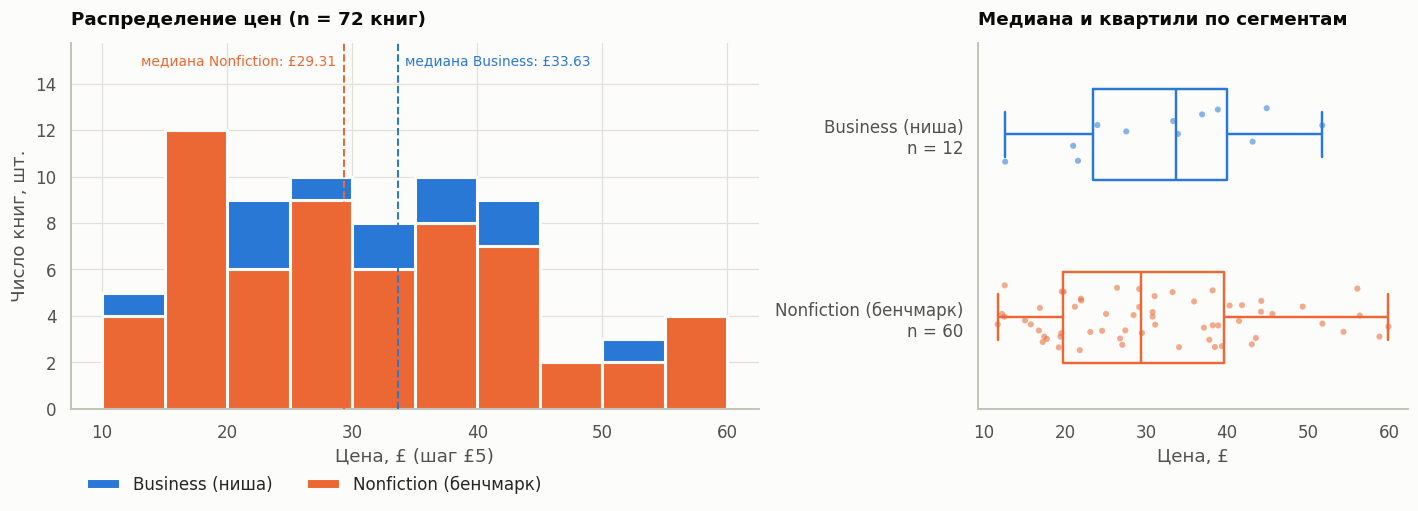

In [13]:
#@title Шаг 5.1. Распределение цен: ниша Business против бенчмарка { display-mode: "form" }
PRICE_BIN = 5                                # ширина корзины гистограммы, £
prices = df_web.dropna(subset=["price"])
seg_n = prices["segment"].value_counts()
seg_median = prices.groupby("segment")["price"].median()
bins = np.arange(np.floor(prices["price"].min() / PRICE_BIN) * PRICE_BIN,
                 prices["price"].max() + PRICE_BIN, PRICE_BIN)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1.6, 1]})
sns.histplot(data=prices, x="price", hue="segment", hue_order=SEG_ORDER, palette=SEG_COLORS,
             bins=bins, multiple="stack", edgecolor=SURFACE, linewidth=2, alpha=1, ax=ax1)
sns.move_legend(ax1, "upper left", bbox_to_anchor=(0, -0.14), ncol=2, title=None)
add_headroom(ax1)
ax1.yaxis.set_major_locator(plt.MaxNLocator(integer=True))
for seg in SEG_ORDER:    # подпись меньшей медианы — слева от линии, большей — справа
    ref_line(ax1, seg_median[seg], f"медиана {seg.split()[0]}: £{seg_median[seg]:.2f}",
             color=SEG_COLORS[seg], side="before" if seg == seg_median.idxmin() else "after")
ax1.set(title=f"Распределение цен (n = {len(prices)} книг)",
        xlabel=f"Цена, £ (шаг £{PRICE_BIN})", ylabel="Число книг, шт.")

sns.boxplot(data=prices, x="price", y="segment", order=SEG_ORDER, hue="segment",
            hue_order=SEG_ORDER, palette=SEG_COLORS, legend=False, fill=False, width=0.5,
            linewidth=1.6, showfliers=False, ax=ax2)
sns.stripplot(data=prices, x="price", y="segment", order=SEG_ORDER, hue="segment",
              hue_order=SEG_ORDER, palette=SEG_COLORS, legend=False, size=4, alpha=0.55,
              jitter=0.18, ax=ax2)
ax2.set_yticks(range(len(SEG_ORDER)), [f"{s}\nn = {seg_n.get(s, 0)}" for s in SEG_ORDER])
ax2.set(title="Медиана и квартили по сегментам", xlabel="Цена, £", ylabel="")
ax2.grid(axis="x")
plt.tight_layout()
plt.show()

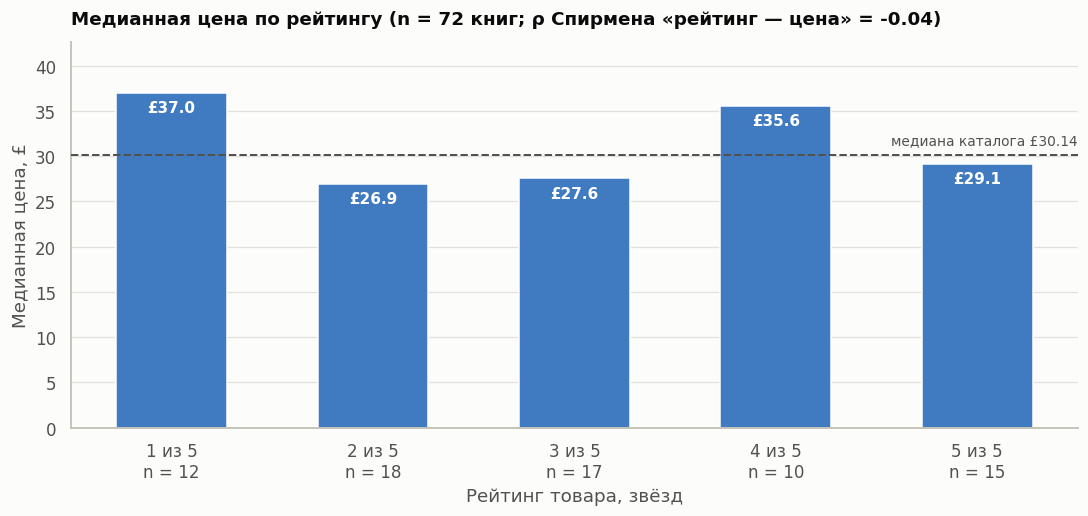

In [14]:
#@title Шаг 5.2. Медианная цена по рейтингу { display-mode: "form" }
by_rating = (df_web.dropna(subset=["price", "rating"]).astype({"rating": int})
             .groupby("rating")["price"].agg(median="median", n="size")
             .reindex(range(1, 6)).rename_axis("rating").reset_index())
# ρ Спирмена = корреляция Пирсона между рангами (так не нужен scipy)
rho = df_web["price"].rank().corr(df_web["rating"].astype(float).rank())
overall_median = df_web["price"].median()

fig, ax = plt.subplots(figsize=(10, 4.8))
sns.barplot(data=by_rating, x="rating", y="median", color=ACCENT, width=0.55, ax=ax)
for i, row in by_rating.iterrows():          # значение — внутри столбца, у его вершины
    if pd.notna(row["median"]):
        ax.text(i, row["median"] - 0.8, f"£{row['median']:.1f}", ha="center", va="top",
                fontsize=10, fontweight="bold", color="white")
ref_line(ax, overall_median, f"медиана каталога £{overall_median:.2f}", orient="h", pos=1.0)
ax.set_xticks(range(5), [f"{r} из 5\nn = {0 if pd.isna(n) else int(n)}"
                         for r, n in zip(by_rating["rating"], by_rating["n"])])
ax.set_ylim(0, by_rating["median"].max() * 1.15)
ax.set(title=f"Медианная цена по рейтингу (n = {int(by_rating['n'].sum())} книг; "
             f"ρ Спирмена «рейтинг — цена» = {rho:.2f})",
       xlabel="Рейтинг товара, звёзд", ylabel="Медианная цена, £")
plt.tight_layout()
plt.show()

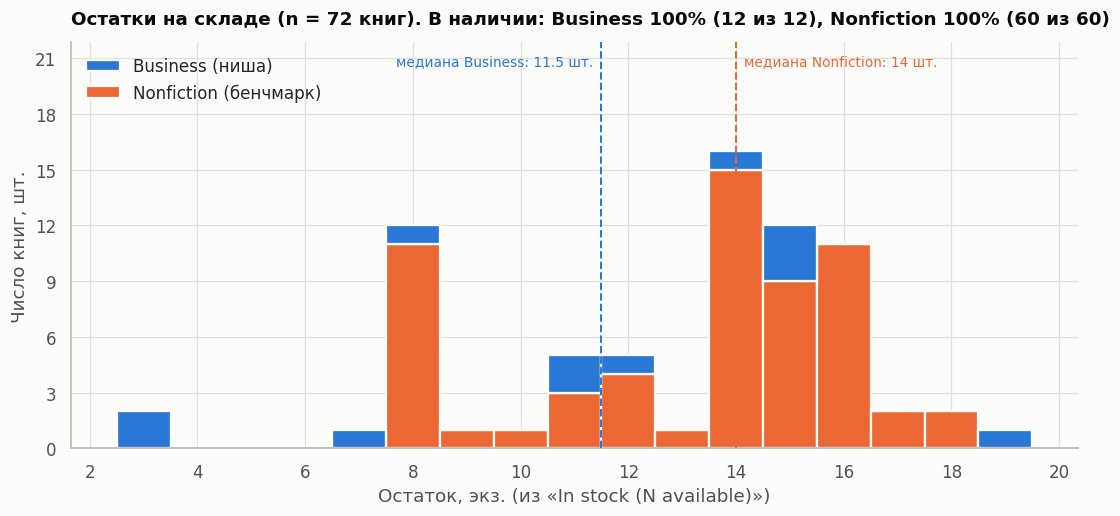

In [15]:
#@title Шаг 5.3. Наличие и глубина остатков { display-mode: "form" }
stock = df_web.dropna(subset=["stock"]).astype({"stock": int})
share_in_stock = df_web.groupby("segment")["in_stock"].agg(["mean", "sum", "size"])
share_text = ", ".join(f"{seg.split()[0]} {r['mean']:.0%} ({int(r['sum'])} из {int(r['size'])})"
                       for seg, r in share_in_stock.reindex(SEG_ORDER).iterrows())
stock_median = stock.groupby("segment")["stock"].median()

fig, ax = plt.subplots(figsize=(10, 4.8))
sns.histplot(data=stock, x="stock", hue="segment", hue_order=SEG_ORDER, palette=SEG_COLORS,
             discrete=True, multiple="stack", edgecolor=SURFACE, linewidth=1.5, alpha=1, ax=ax)
sns.move_legend(ax, "upper left", title=None)
add_headroom(ax, 1.3)
for seg in SEG_ORDER:
    ref_line(ax, stock_median[seg], f"медиана {seg.split()[0]}: {stock_median[seg]:g} шт.",
             color=SEG_COLORS[seg], side="before" if seg == stock_median.idxmin() else "after")
ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax.yaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax.set(title=f"Остатки на складе (n = {len(stock)} книг). В наличии: {share_text}",
       xlabel="Остаток, экз. (из «In stock (N available)»)", ylabel="Число книг, шт.")
plt.tight_layout()
plt.show()

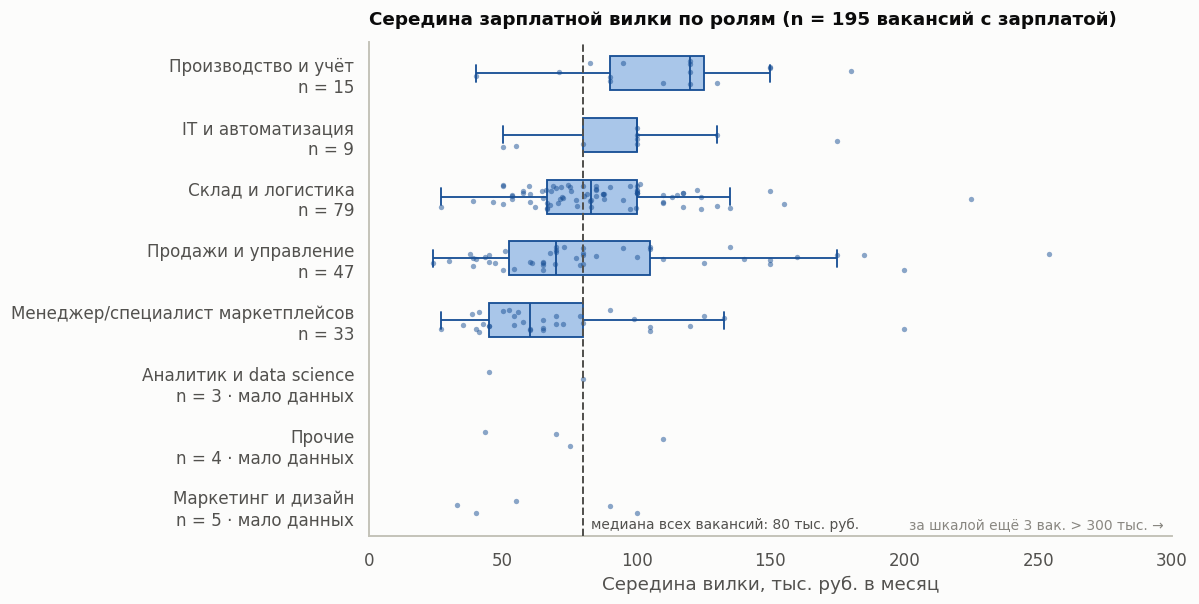

In [16]:
#@title Шаг 5.4. Boxplot зарплат по ролям { display-mode: "form" }
sal = df_api.dropna(subset=["salary_mid"]).assign(salary_k=lambda d: d["salary_mid"] / 1000)
role_n = sal["role"].value_counts()
MIN_BOX_N = 8              # квартили по 3–5 точкам — не закономерность: такие группы без «коробки»
role_median = sal.groupby("role")["salary_k"].median()
big = role_median[role_n.reindex(role_median.index) >= MIN_BOX_N].sort_values(ascending=False)
small = role_median.drop(big.index).sort_values(ascending=False)
role_order = big.index.tolist() + small.index.tolist()      # малые группы — внизу
salary_median_k = sal["salary_k"].median()
X_LIMIT_K = 300            # единичные вилки выше 300 тыс. сжимают шкалу — показываем их числом
hidden = int((sal["salary_k"] > X_LIMIT_K).sum())

fig, ax = plt.subplots(figsize=(11, 5.6))
sns.boxplot(data=sal[sal["role"].isin(big.index)], x="salary_k", y="role", order=role_order,
            color=ACCENT_LIGHT, linecolor=ACCENT_DARK, linewidth=1.2, width=0.55,
            showfliers=False, ax=ax)
sns.stripplot(data=sal, x="salary_k", y="role", order=role_order, color=ACCENT_DARK,
              size=3.5, alpha=0.5, jitter=0.2, ax=ax)
ref_line(ax, salary_median_k, f"медиана всех вакансий: {salary_median_k:.0f} тыс. руб.",
         pos=0.01)
ax.set_xlim(0, X_LIMIT_K)
if hidden:
    ax.annotate(f"за шкалой ещё {hidden} вак. > {X_LIMIT_K} тыс. →", xy=(0.99, 0.01),
                xycoords="axes fraction", ha="right", va="bottom", fontsize=9, color=MUTED)
ax.set_yticks(range(len(role_order)),
              [f"{r}\nn = {role_n[r]}" + ("" if r in big.index else " · мало данных")
               for r in role_order])
ax.set(title=f"Середина зарплатной вилки по ролям (n = {len(sal)} вакансий с зарплатой)",
       xlabel="Середина вилки, тыс. руб. в месяц", ylabel="")
ax.grid(axis="x")
plt.tight_layout()
plt.show()

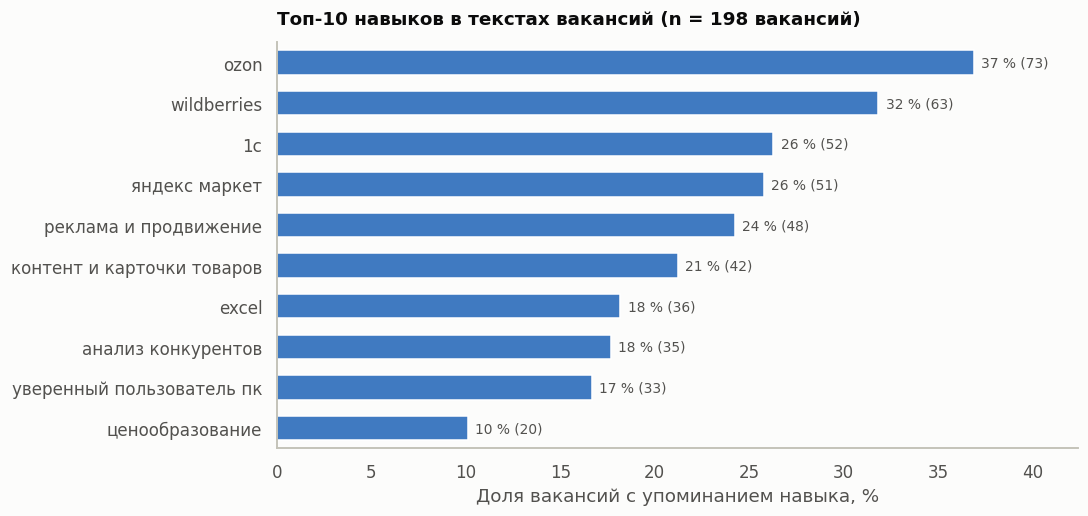

In [17]:
#@title Шаг 5.5. Топ-10 навыков в вакансиях { display-mode: "form" }
skill_counts = df_api["skills"].explode().dropna().value_counts()
top_skills = skill_counts.head(10).rename_axis("skill").reset_index(name="n")
top_skills["share"] = top_skills["n"] / len(df_api) * 100

fig, ax = plt.subplots(figsize=(10, 4.8))
sns.barplot(data=top_skills, x="share", y="skill", color=ACCENT, width=0.6, ax=ax)
for i, row in top_skills.iterrows():
    ax.text(row["share"] + 0.4, i, f"{row['share']:.0f} % ({row['n']})", va="center",
            fontsize=9, color=INK_2)
ax.set_xlim(0, top_skills["share"].max() * 1.15)
ax.set(title=f"Топ-10 навыков в текстах вакансий (n = {len(df_api)} вакансий)",
       xlabel="Доля вакансий с упоминанием навыка, %", ylabel="")
ax.grid(axis="x")
plt.tight_layout()
plt.show()

**Как читать вывод.** На гистограмме цен смотрите не на среднее, а на форму: длинный правый хвост означает, что несколько дорогих позиций тянут среднее вверх, и для отчёта корректнее медиана. На графике цен по рейтингу обращайте внимание на подписи `n=`: медиана по трём товарам — это не закономерность. На распределении остатков важна доля позиций в наличии: это прямой индикатор качества управления запасами у конкурента. На боксплоте зарплат сравнивайте медианы и ширину коробок: широкая коробка означает, что в одной и той же роли рынок платит очень по-разному, и нанимать придётся точечно.

**Что показывают графики (вариант 2).**

1. **Распределение цен.** Медиана ниши Business — £33.63, у Nonfiction — £29.31: премия **+14,7 %**. Верхний квартиль почти одинаковый (£39.92 и £39.60), поэтому премия создаётся снизу. Дешевле £20 в нише 1 книга из 12 (8 %), в бенчмарке — 16 из 60 (27 %). У Nonfiction длиннее правый хвост: до £59.90 против £51.74.
2. **Цена по рейтингу.** Связи нет: ρ Спирмена = −0,04. Самая высокая медиана — у книг с одной звездой (£37.0, n = 12). У пятизвёздочных она ниже медианы каталога (£29.1 против £30.14). Отклонения столбцов от медианы каталога (от −£3 до +£7) при n = 10–18 — шум, а не премия за качество. Для этой витрины это ожидаемо: по её же предупреждению цены и рейтинги назначены случайно.
3. **Наличие.** В наличии 100 % позиций обоих сегментов (12 из 12 и 60 из 60), но запас ниши тоньше: медиана 11,5 экз. против 14. Обе позиции с остатком не больше 5 экз. (по 3 экз.) — из Business.
4. **Зарплаты.** Медиана середины вилки по выборке — 80 тыс. руб. Специалисты маркетплейсов (33 вакансии с зарплатой) получают меньше: медиана 60 тыс., Q1–Q3 — 45–80 тыс. Самая широкая коробка у «Продаж и управления» (52,5–105 тыс.): в одной и той же роли рынок платит очень по-разному. Аналитиков всего 3 — для коробки этого мало.
5. **Навыки.** Лидируют площадки и операционные задачи: Ozon (37 % вакансий), Wildberries (32 %), 1С (26 %), Яндекс Маркет (26 %), реклама (24 %), контент и карточки (21 %). Базовая компьютерная грамотность («уверенный пользователь ПК») встречается в 17 % вакансий. Классического аналитического стека (Python, SQL, BI) в топ-10 нет.

### Шаг 6. Выводы и управленческие рекомендации

**Зачем мы это делаем.** Заказчику нужны не графики, а решения: входить ли в нишу, по какой цене, хватит ли на рынке специалистов. Метрики считаем кодом, а в текст переносим уже посчитанные значения — так вывод невозможно «придумать».

In [18]:
#@title Шаг 6. Метрики для выводов: считаем, а не придумываем { display-mode: "form" }
def safe(series, func, default=float("nan")):
    s = pd.to_numeric(series, errors="coerce").dropna() if series is not None else pd.Series(dtype=float)
    return func(s) if len(s) else default

metrics = {
    "товаров собрано": len(df_web),
    "медианная цена": safe(df_web.get("price"), lambda s: round(s.median(), 2)),
    "разброс цен (IQR)": safe(df_web.get("price"), lambda s: round(s.quantile(.75) - s.quantile(.25), 2)),
    "доля в наличии": (round(float((df_web["stock"].fillna(0) > 0).mean()), 3)
                       if "stock" in df_web else float("nan")),
    "средний рейтинг": safe(df_web.get("rating"), lambda s: round(s.mean(), 2)),
    "вакансий собрано": len(df_api),
    "медиана вилки, руб.": safe(df_api.get("salary_mid"), lambda s: round(s.median())),
    "доля вакансий с зарплатой": (round(float(df_api["salary_mid"].notna().mean()), 3)
                                  if "salary_mid" in df_api else float("nan")),
    "доля удалённых вакансий": (round(float(df_api["is_remote"].mean()), 3)
                                if "is_remote" in df_api else float("nan")),
}
summary = pd.Series(metrics, name="значение").to_frame()
display(summary)

print(f"Источники: API — {API_SOURCE}; сайт — {WEB_SOURCE}. "
      f"Запросов выполнено: {len(REQUEST_LOG)}, из них с ошибкой: "
      f"{sum(1 for m in REQUEST_LOG if m.get('error'))}.")
if API_SOURCE == "synthetic" or WEB_SOURCE == "offline-snapshot":
    print("⚠ Часть данных получена в аварийном режиме — в отчёте это нужно указать явно, "
          "а выводы перепроверить на реальных данных.")

,значение
товаров собрано,72.000
медианная цена,30.140
разброс цен (IQR),18.440
доля в наличии,1.000
средний рейтинг,2.970
вакансий собрано,198.000
"медиана вилки, руб.",80000.000
доля вакансий с зарплатой,0.985
доля удалённых вакансий,0.056


Источники: API — trudvsem; сайт — books. Запросов выполнено: 81, из них с ошибкой: 0.


### Шаг 6.1. Метрики позиционирования

**Зачем мы это делаем.** Базовая таблица метрик описывает выборку целиком. Для решения о цене нужно сравнить нишу с бенчмарком: квартили, премию по медиане, наличие. А для решения о найме нужна вилка по ролям. Все числа для выводов берутся отсюда.

In [19]:
#@title Шаг 6.1. Метрики позиционирования и рынка труда { display-mode: "form" }
def quantile(p):
    """Агрегатор-квантиль для groupby.agg."""
    return lambda s: s.quantile(p)


positioning = (df_web.groupby("segment")
               .agg(n=("price", "size"), min=("price", "min"), q1=("price", quantile(.25)),
                    median=("price", "median"), q3=("price", quantile(.75)),
                    max=("price", "max"), mean=("price", "mean"), in_stock=("in_stock", "mean"),
                    stock_median=("stock", "median"), rating_mean=("rating", "mean"))
               .reindex(SEG_ORDER))
positioning["iqr"] = positioning["q3"] - positioning["q1"]
display(positioning.round(2))

niche, bench = SEG_ORDER
niche_prices = df_web.loc[df_web["segment"] == niche, "price"]
premium = positioning.loc[niche, "median"] / positioning.loc[bench, "median"] - 1
above_bench = (niche_prices > positioning.loc[bench, "median"]).mean()
print(f"Ценовая премия ниши к бенчмарку (по медианам): {premium:+.1%}")
print(f"Доля книг ниши дороже медианы бенчмарка: {above_bench:.0%}")
print(f"Ценовой коридор входа: £{positioning.loc[bench, 'median']:.2f} (медиана бенчмарка) – "
      f"£{positioning.loc[niche, 'q3']:.2f} (Q3 ниши), якорь — медиана ниши "
      f"£{positioning.loc[niche, 'median']:.2f}, нижняя граница — Q1 ниши "
      f"£{positioning.loc[niche, 'q1']:.2f}")
print(f"Связь рейтинга и цены (ρ Спирмена, все книги): {rho:.2f}")
CHEAP_PRICE = 20            # граница «бюджетного» сегмента, £
cheap = (df_web["price"] < CHEAP_PRICE).groupby(df_web["segment"]).agg(["sum", "size"])
print(f"Книги дешевле £{CHEAP_PRICE}:",
      {s: f"{r['sum']} из {r['size']} ({r['sum'] / r['size']:.0%})"
       for s, r in cheap.reindex(SEG_ORDER).iterrows()})
low_stock = df_web[df_web["stock"] <= 5]
print(f"Позиции с остатком ≤ 5 экз.: {len(low_stock)} — "
      f"{low_stock['segment'].value_counts().to_dict()}\n")

roles = (df_api.groupby("role")
         .agg(n=("vacancy_id", "size"), with_salary=("salary_mid", "count"),
              q1=("salary_mid", quantile(.25)), median=("salary_mid", "median"),
              q3=("salary_mid", quantile(.75)), remote=("is_remote", "mean"))
         .sort_values("median", ascending=False))
display(roles.round({"q1": 0, "median": 0, "q3": 0, "remote": 3}))

analysts = df_api[df_api["role"] == ROLE_RULES[0][0]]      # «Аналитик и data science»
print(f"Аналитиков в выборке: {len(analysts)}; медиана середины вилки: "
      f"{analysts['salary_mid'].median():,.0f} руб.".replace(",", " "))
print("Топ-5 регионов по числу вакансий:", df_api["region"].value_counts().head(5).to_dict())
print("Топ-5 навыков:", skill_counts.head(5).to_dict())

# «Ядро» команды для запуска ниши на маркетплейсах: аналитики + специалисты маркетплейсов
core = df_api[df_api["role"].isin([ROLE_RULES[0][0], ROLE_RULES[2][0]])]
core_q = core["salary_mid"].quantile([.25, .5, .75])
core_skills = core["skills"].explode().dropna().value_counts()
print(f"\nЯдро команды: {len(core)} вакансий; середина вилки Q1 / медиана / Q3: "
      f"{core_q[.25]:,.0f} / {core_q[.5]:,.0f} / {core_q[.75]:,.0f} руб.".replace(",", " "))
CAPITAL = ["Город Москва", "Московская область"]
print(f"Доля ядра вне Москвы и МО: {(~core['region'].isin(CAPITAL)).mean():.0%}; "
      f"удалённо: {core['is_remote'].mean():.0%}")
print("Топ-6 навыков ядра, % вакансий:",
      (core_skills.head(6) / len(core) * 100).round().astype(int).to_dict())

,n,min,q1,median,q3,max,mean,in_stock,stock_median,rating_mean,iqr
segment,,,,,,,,,,,
Business (ниша),12,12.61,23.39,33.63,39.92,51.74,32.46,1.0,11.5,2.92,16.53
Nonfiction (бенчмарк),60,11.68,19.77,29.31,39.60,59.90,31.22,1.0,14.0,2.98,19.82


Ценовая премия ниши к бенчмарку (по медианам): +14.7%
Доля книг ниши дороже медианы бенчмарка: 58%
Ценовой коридор входа: £29.31 (медиана бенчмарка) – £39.92 (Q3 ниши), якорь — медиана ниши £33.63, нижняя граница — Q1 ниши £23.39
Связь рейтинга и цены (ρ Спирмена, все книги): -0.04
Книги дешевле £20: {'Business (ниша)': '1 из 12 (8%)', 'Nonfiction (бенчмарк)': '16 из 60 (27%)'}
Позиции с остатком ≤ 5 экз.: 2 — {'Business (ниша)': 2}



,n,with_salary,q1,median,q3,remote
role,,,,,,
Производство и учёт,15,15,90000.0,120000.0,125000.0,0.000
IT и автоматизация,9,9,80000.0,100000.0,100000.0,0.222
Склад и логистика,80,79,66675.0,82800.0,100000.0,0.012
Аналитик и data science,3,3,62500.0,80000.0,248000.0,0.000
Прочие,4,4,63337.0,72500.0,83750.0,0.250
Продажи и управление,48,47,52500.0,70000.0,105000.0,0.062
Менеджер/специалист маркетплейсов,34,33,45000.0,60000.0,80000.0,0.088
Маркетинг и дизайн,5,5,40000.0,55000.0,90000.0,0.200


Аналитиков в выборке: 3; медиана середины вилки: 80 000 руб.
Топ-5 регионов по числу вакансий: {'Город Москва': 53, 'Московская область': 29, 'Свердловская область': 9, 'Ульяновская область': 8, 'Ростовская область': 8}
Топ-5 навыков: {'ozon': 73, 'wildberries': 63, '1с': 52, 'яндекс маркет': 51, 'реклама и продвижение': 48}

Ядро команды: 37 вакансий; середина вилки Q1 / медиана / Q3: 45 000 / 62 500 / 82 500 руб.
Доля ядра вне Москвы и МО: 73%; удалённо: 8%
Топ-6 навыков ядра, % вакансий: {'контент и карточки товаров': 68, 'реклама и продвижение': 57, 'анализ конкурентов': 49, 'excel': 46, 'ozon': 38, '1с': 35}


**Как читать вывод.** Таблица метрик — фактура для отчёта. Проверьте строку об источниках: если хотя бы один из них аварийный, выводы помечаются как предварительные. Ниже — шаблон управленческого вывода: каждая рекомендация должна опираться на конкретное число из этой таблицы и содержать действие, а не наблюдение.

### Ваши выводы и рекомендации

**1. Что собрано.**

* **Дата сбора:** 16.10.2026, 22:00 МСК. Данные реальные, аварийные режимы не включались.
* **API «Работа в России»** ([trudvsem.ru](https://trudvsem.ru), открытые данные Роструда, без ключа): **198 уникальных вакансий** по всей России, без фильтра по региону. Из них 20 — по запросу варианта «аналитик маркетплейсов» (вся выдача), 178 — по расширяющему запросу «маркетплейс» (шаг 1.2: по параметрам варианта минимум в 50 записей не набирался). Пагинация по 100 записей, остановка на неполной странице.
* **books.toscrape.com:** **72 книги** — вся ниша Business (12 шт., 1 страница; параметр варианта «3 страницы» недостижим) и бенчмарк Nonfiction (60 шт., 3 страницы), плюс 72 страницы товаров для остатков.
* **Как собирали:** 81 HTTP-запрос с паузой 0,5 с и ретраями, ошибок нет (журнал — шаг 3.5). `robots.txt` проверен (шаг 1.3). У витрины его нет. У opendata.trudvsem.ru он запрещает обход роботам, поэтому используется только документированное API открытых данных.
* **Условия использования:** данные вакансий — © Федеральная служба по труду и занятости, при копировании ссылка на trudvsem.ru обязательна (отдельная лицензия на портале не названа). books.toscrape.com — учебная витрина для тренировки парсинга. Персональные данные (контакты, ФИО, адреса) не собирались, работодатели обезличены.

**2. Что показывают данные.**

1. **Ниша дороже смежного рынка.** Медиана Business £33.63 против £29.31 у Nonfiction (+14,7 %), и 58 % книг ниши дороже медианы бенчмарка. Верх рынка одинаковый (Q3 £39.92 и £39.60): премия возникает потому, что у конкурента в нише почти нет дешёвого сегмента — дешевле £20 лишь 1 книга из 12 (8 %) против 16 из 60 (27 %) в бенчмарке.
2. **Рейтинг цену не объясняет.** ρ Спирмена = −0,04. Медиана пятизвёздочных книг (£29.1) ниже медианы каталога (£30.14), а самые дорогие — однозвёздочные (£37.0).
3. **Наличие полное, но запас в нише тоньше.** В наличии 100 % позиций обоих сегментов (12 из 12 и 60 из 60). Медианный остаток 11,5 экз. против 14, и обе позиции с остатком 3 экз. — из Business.
4. **Целевых «аналитиков маркетплейсов» в открытых данных почти нет:** 3 вакансии из 198. «Ядро» команды для запуска (аналитики и специалисты маркетплейсов) — 37 вакансий. Медиана середины вилки 62 500 руб. (Q1–Q3: 45 000–82 500), это ниже медианы всей выборки (80 000 руб.). 73 % таких вакансий — вне Москвы и области, удалённых — 8 %.
5. **Работодатели ищут операционные, а не аналитические навыки.** В вакансиях ядра чаще всего встречаются контент и карточки товаров (68 %), реклама и продвижение (57 %), анализ конкурентов (49 %), Excel (46 %), Ozon (38 %) и 1С (35 %).

**3. Управленческие рекомендации.**

| № | Действие | Основание | Ожидаемый эффект | Как проверить |
|---|---|---|---|---|
| 1 | Основной ассортимент деловой литературы выставлять в коридоре **£29.31–39.92** (от медианы бенчмарка до Q3 ниши) с якорем на медиане ниши **£33.63** и не опускаться ниже Q1 ниши (£23.39). Наценку за рейтинг не закладывать | Премия ниши к нон-фикшн +14,7 %, 58 % книг ниши дороже медианы бенчмарка; связи рейтинга и цены нет (ρ = −0,04) | Попадание в основной ценовой коридор конкурента без демпинга и маржа выше, чем в нон-фикшн | A/B-тест двух уровней цены (у нижней границы коридора и у якоря) на 2–3 позициях в течение месяца; метрики — конверсия и маржа на заказ |
| 2 | Протестировать **бюджетную линейку дешевле £20** на 2–3 позициях | У конкурента в нише дешевле £20 только 1 книга из 12 (8 %), в смежном нон-фикшн — 16 из 60 (27 %): спрос на сегмент есть, предложения в нише почти нет | Захват ценочувствительных покупателей, которых конкурент не обслуживает | Продажи и доля новых клиентов бюджетной линейки за 1–2 месяца против основной линейки |
| 3 | Нанимать **специалиста по маркетплейсам с аналитическими задачами**, а не искать узкого «аналитика маркетплейсов»: бюджет **62 500 руб.** (медиана ядра), до **82 500 руб.** (Q3) для сильного кандидата; в профиле — карточки, реклама, анализ конкурентов, Excel; искать в регионах и предлагать удалёнку | Узких аналитиков на рынке 3 из 198; ядро — 37 вакансий, Q1–Q3 45 000–82 500 руб.; 73 % вакансий ядра вне Москвы и области, удалённых всего 8 % | Закрытие вакансии по рыночной цене; удалёнка — конкурентное преимущество при найме | Время закрытия вакансии и число откликов за 30 дней при вилке на уровне медианы–Q3 |

**4. Ограничения и риски вывода.**

* **Главное:** books.toscrape.com — учебная витрина, и на её главной странице прямо сказано: *«Prices and ratings here were randomly assigned and have no real meaning»*. Отсутствие связи рейтинга и цены здесь ожидаемо, а ценовые рекомендации — упражнение на методику. На реальный рынок переносится способ расчёта, а не сами числа.
* Ниша — всего 12 книг: одна позиция сдвигает квартиль на несколько фунтов, поэтому выводы о цене предварительные. Nonfiction — смежный, но не идентичный сегмент.
* Один срез (17.10.2026), динамики цен и остатков нет.
* Вакансии — только портал «Работа в России»: hh.ru с апреля 2026 закрыт для неавторизованных запросов. Поиск по ключевому слову нечёткий: в выдаче «аналитик маркетплейсов» встречаются директора и сисадмины.
* `robots.txt` хоста API запрещает обход роботам. Мы опираемся на то, что владелец сам публикует документированное API открытых данных (шаг 1.3), но преподаватель может трактовать это строже.
* 20 % вакансий — почти дубли (задание C), поэтому структура выборки смещена к массовому складскому найму.
* В тексте зарплата указана только как «от N»; верхнюю границу дало числовое поле API у 116 из 195 вакансий. Навыки ищутся по словарю (найдены у 83,3 % вакансий), роли размечены правилами (не классифицировано 2 %).

**5. Что делать дальше.**

* Повторять сбор каталога и остатков еженедельно, сохраняя снимки с меткой времени (задание D): это даст динамику цен и наличия. Отдельно следить за остатками конкурента: у него медианный запас в нише 11,5 экз., а 2 позиции — всего по 3 экз. Это окно для перехвата спроса, если позиции закончатся.
* Добрать вакансии из других источников: hh.ru через зарегистрированное приложение, SuperJob API. Целевые роли — «менеджер маркетплейсов», «аналитик Wildberries/Ozon».
* Для реального решения повторить методику на категории «Бизнес-литература» реальных площадок с соблюдением их правил использования данных.
* Встроить дедупликацию вакансий (J ≥ 0,8) в основной пайплайн перед расчётом метрик.

## Таблица вариантов (30 вариантов)

Номер варианта выдаёт преподаватель. Параметры подставляются в код автоматически по значению `VARIANT` из шага 1. Вариант 30 разобран в версии для преподавателя как эталон.

Минимальный объём выборки для зачёта по блоку 1: **не менее 50 записей из API** и **не менее 40 карточек с сайта**. Если на вашем запросе данных меньше — расширьте ключевое слово или глубину пагинации и зафиксируйте это в отчёте.

| № | Сфера | Бизнес-задача | Источник API | Сайт для парсинга | Параметры сбора | Целевые метрики и визуализации |
|---:|---|---|---|---|---|---|
| 1 | HR-аналитика | Рынок труда AI/ML-инженеров: где искать кадры и сколько они стоят | opendata.trudvsem.ru | books.toscrape.com | API: text=инженер машинного обучения, pages=5, per_page=100<br>Сайт: category=science_22, pages=3 | Медиана и IQR зарплатной вилки по регионам; топ-10 работодателей; доля вакансий с удалённой работой; гистограмма цен каталога |
| 2 | E-commerce | Ценовое позиционирование в нише деловой литературы | opendata.trudvsem.ru | books.toscrape.com | API: text=аналитик маркетплейсов, pages=4, per_page=100<br>Сайт: category=business_35, pages=3 | Распределение цен, медиана по рейтингу, доля товаров в наличии, boxplot зарплат |
| 3 | Финтех | Валютный риск закупок: динамика USD и EUR за квартал | cbr.ru | books.toscrape.com | API: currencies=['USD', 'EUR'], days=90<br>Сайт: category=travel_2, pages=2 | Линейный график курсов, дневная волатильность (std доходностей), пересчёт цен каталога в рубли |
| 4 | Мониторинг конкурентов | Сравнение ассортимента двух товарных категорий | api.github.com | books.toscrape.com | API: q=price monitoring, sort=stars, pages=2, per_page=50<br>Сайт: category=fiction_10, pages=4 | Boxplot цен по категориям, топ-10 репозиториев по звёздам, scatter «звёзды — форки» |
| 5 | Наука и инновации | Научная активность в сфере FinTech: динамика публикаций | api.openalex.org | quotes.toscrape.com | API: search=fintech, from_year=2019, per_page=100, pages=2<br>Сайт: tag=inspirational, pages=4 | Публикации по годам, топ-10 организаций, доля open access, частотный анализ тегов |
| 6 | Логистика | Погодные риски на складских хабах: планирование окон отгрузки | api.open-meteo.com | books.toscrape.com | API: cities=['Москва', 'Екатеринбург', 'Новосибирск'], days=14<br>Сайт: category=history_32, pages=2 | Температура и осадки по хабам, число «рисковых» дней, медиана цен каталога |
| 7 | HR-аналитика | Спрос на дата-инженеров и требования к стеку | opendata.trudvsem.ru | quotes.toscrape.com | API: text=инженер данных, pages=5, per_page=100<br>Сайт: tag=life, pages=3 | Топ-15 технологий в требованиях (RegEx), медиана зарплат по опыту, облако тегов цитат |
| 8 | E-commerce | Влияние рейтинга на цену: есть ли премия за качество | api.github.com | books.toscrape.com | API: q=recommender system, sort=stars, pages=2, per_page=50<br>Сайт: category=romance_8, pages=4 | Scatter «рейтинг — цена» с линией тренда, ANOVA-подобное сравнение медиан, топ репозиториев |
| 9 | Финтех | Стоимость валютной корзины импортёра | cbr.ru | webscraper.io/test-sites/e-commerce/allinone | API: currencies=['USD', 'EUR', 'CNY'], days=120<br>Сайт: section=computers/laptops, pages=3 | Индекс корзины (веса 0.5/0.3/0.2), максимальная просадка, цены ноутбуков в рублях по курсу |
| 10 | Мониторинг конкурентов | Глубина ассортимента и «дыры» в наличии у конкурента | opendata.trudvsem.ru | books.toscrape.com | API: text=категорийный менеджер, pages=4, per_page=100<br>Сайт: category=mystery_3, pages=4 | Доля out-of-stock, распределение остатков (RegEx из «In stock (N available)»), топ регионов по вакансиям |
| 11 | Наука и инновации | Публикационный ландшафт по теме «supply chain analytics» | api.openalex.org | scrapethissite.com/pages | API: search=supply chain analytics, from_year=2020, per_page=100, pages=2<br>Сайт: section=countries, pages=1 | Динамика публикаций, топ стран и организаций, связь числа публикаций с населением стран |
| 12 | Логистика | Температурный режим перевозок: risk-календарь на две недели | api.open-meteo.com | webscraper.io/test-sites/e-commerce/allinone | API: cities=['Санкт-Петербург', 'Казань', 'Краснодар'], days=14<br>Сайт: section=computers/tablets, pages=3 | Heatmap «город — день», доля дней с t < 0 °C, медианы цен планшетов |
| 13 | HR-аналитика | BI-аналитики: сколько стоит и что требуют работодатели | opendata.trudvsem.ru | books.toscrape.com | API: text=BI аналитик, pages=5, per_page=100<br>Сайт: category=business_35, pages=3 | Топ навыков (Power BI, SQL, Python, 1С), медиана вилки, распределение по типам занятости |
| 14 | Технологические тренды | Экосистема инструментов парсинга: кто лидирует | api.github.com | quotes.toscrape.com | API: q=web scraping, sort=stars, pages=2, per_page=50<br>Сайт: tag=books, pages=3 | Топ-15 репозиториев, распределение по языкам, возраст проекта vs звёзды |
| 15 | E-commerce | Ценовые сегменты в детской нише: где «дыра» в предложении | opendata.trudvsem.ru | books.toscrape.com | API: text=менеджер интернет-магазина, pages=4, per_page=100<br>Сайт: category=childrens_11, pages=4 | Гистограмма цен с квантилями, разбиение на сегменты (low/mid/high), топ работодателей |
| 16 | Финтех | Курс юаня и импорт электроники: чувствительность цены | cbr.ru | webscraper.io/test-sites/e-commerce/allinone | API: currencies=['CNY'], days=180<br>Сайт: section=phones/touch, pages=2 | Динамика CNY, скользящее среднее 7 дней, пересчёт цен телефонов при ±10 % курса |
| 17 | Наука и инновации | Исследования по «digital twin» в промышленности | api.openalex.org | books.toscrape.com | API: search=digital twin manufacturing, from_year=2018, per_page=100, pages=2<br>Сайт: category=science_22, pages=3 | Динамика по годам, топ-10 авторов, доля OA, медиана цитируемости |
| 18 | Мониторинг конкурентов | Сравнение цен и «звёздности» ассортимента двух категорий | api.github.com | books.toscrape.com | API: q=e-commerce analytics, sort=stars, pages=2, per_page=50<br>Сайт: category=food-and-drink_33, pages=3 | Две категории на одном boxplot, доля 4–5★, топ open-source решений для e-com аналитики |
| 19 | HR-аналитика | Логистические профессии: дефицит кадров по регионам | opendata.trudvsem.ru | scrapethissite.com/pages | API: text=логист, pages=6, per_page=100<br>Сайт: section=countries, pages=1 | Топ-15 регионов по числу вакансий, медиана зарплат, связь с площадью/населением стран (демо-джойн) |
| 20 | Логистика | Окна доставки в северных хабах на горизонте 16 дней | api.open-meteo.com | books.toscrape.com | API: cities=['Мурманск', 'Архангельск', 'Якутск'], days=16<br>Сайт: category=travel_2, pages=2 | Линии температур, число дней с осадками, стоимость «северной надбавки» как гипотеза |
| 21 | E-commerce | Автоматизация мониторинга: как часто меняется наличие товара | api.github.com | books.toscrape.com | API: q=price tracker, sort=stars, pages=2, per_page=50<br>Сайт: category=sequential-art_5, pages=4 | Распределение остатков, доля дефицитных позиций, топ инструментов трекинга цен |
| 22 | Финтех | Волатильность рубля как фактор ценообразования | cbr.ru | books.toscrape.com | API: currencies=['USD', 'EUR'], days=365<br>Сайт: category=business_35, pages=3 | Годовая динамика, скользящая волатильность 30 дней, сценарии наценки 5/10/15 % |
| 23 | HR-аналитика | Продуктовые аналитики: требования и вилки | opendata.trudvsem.ru | quotes.toscrape.com | API: text=продуктовый аналитик, pages=5, per_page=100<br>Сайт: tag=humor, pages=3 | Топ навыков, медиана вилки по опыту, доля вакансий без указания зарплаты |
| 24 | Технологические тренды | Инструменты работы с данными: Python-экосистема | api.github.com | webscraper.io/test-sites/e-commerce/allinone | API: q=pandas alternative dataframe, sort=stars, pages=2, per_page=50<br>Сайт: section=computers/laptops, pages=3 | Топ-15 по звёздам, динамика последних обновлений, цена ноутбуков vs объём памяти (RegEx) |
| 25 | Наука и инновации | Публикации по «marketplace pricing»: кто задаёт повестку | api.openalex.org | books.toscrape.com | API: search=marketplace pricing, from_year=2019, per_page=100, pages=2<br>Сайт: category=business_35, pages=3 | Динамика, топ организаций, распределение цитируемости (log-scale), медиана цен каталога |
| 26 | Логистика | Планирование складских смен по погодным окнам | api.open-meteo.com | scrapethissite.com/pages | API: cities=['Ростов-на-Дону', 'Самара', 'Пермь'], days=14<br>Сайт: section=hockey, pages=2 | Доля благоприятных дней по хабам, heatmap, парсинг таблицы с пагинацией |
| 27 | Мониторинг конкурентов | Бенчмарк цен на технику: разброс внутри линейки | opendata.trudvsem.ru | webscraper.io/test-sites/e-commerce/allinone | API: text=менеджер по закупкам, pages=4, per_page=100<br>Сайт: section=computers/laptops, pages=3 | Boxplot цен по брендам (RegEx из названия), коэффициент вариации, медиана зарплат закупщиков |
| 28 | E-commerce | Влияние глубины каталога на средний чек (гипотеза) | api.github.com | books.toscrape.com | API: q=shopping cart analytics, sort=stars, pages=2, per_page=50<br>Сайт: category=poetry_23, pages=4 | Средняя цена по страницам пагинации, кумулятивная кривая ассортимента, топ репозиториев |
| 29 | Финтех | Кросс-курсы и арбитраж: USD, EUR, CNY за полгода | cbr.ru | quotes.toscrape.com | API: currencies=['USD', 'EUR', 'CNY'], days=180<br>Сайт: tag=life, pages=3 | Кросс-курсы EUR/USD и CNY/USD, корреляционная матрица, частотный анализ авторов цитат |
| 30 | E-commerce + HR (эталон преподавателя) | Оценка ниши деловой литературы: ассортимент и цены конкурента плюс доступность кадров для запуска направления | opendata.trudvsem.ru | books.toscrape.com | API: text=аналитик данных, pages=3, per_page=100<br>Сайт: category=business_35, pages=3 | Медиана и квартили цен, цены по рейтингу, доля в наличии, зарплатная вилка по регионам, топ навыков |

## Критерии оценки (до 10 баллов)

| Блок | Что оценивается | Максимум |
|---|---|---:|
| 1. Сбор данных | Корректная пагинация и остановка цикла; паузы и повторные попытки; обработка кодов ответа и исключений (`try/except`, проверка `status_code`); объём выборки не ниже минимума варианта; понятный лог сбора | 25 |
| 2. Очистка, RegEx и XPath | Рабочие селекторы CSS **и** XPath, сверка результатов; регулярные выражения с тестами; доля распознанных значений ≥ 80 %; итоговый `DataFrame` с типизированными колонками | 25 |
| 3. EDA и визуализация | Не менее четырёх графиков из варианта; подписанные оси и единицы измерения; указан объём выборки; выбраны устойчивые метрики (медиана, квартили); графики читаются без пояснений | 25 |
| 4. Бизнес-выводы | Выводы опираются на посчитанные числа; сформулированы действия, а не наблюдения; указаны ожидаемый эффект и способ проверки; честно названы ограничения | 25 |

### Шкала

| Баллы | Оценка |
|---|---|
| 8-10 | отлично |
| 7-8 | хорошо |
| 5-6 | удовлетворительно |
| < 5 | работа возвращается на доработку |

### Штрафы

| Нарушение | Штраф |
|---|---:|
| Ключ, токен или пароль в коде либо в выводе ячейки | −1,5 и обязательный отзыв ключа |
| Сбор без пауз и обработки ошибок («жёсткий» цикл по страницам) | −1,0 |
| Выводы на аварийных (синтетических) данных без указания этого факта | −1,0 |
| Разбор HTML регулярными выражениями вместо парсера | −0,5 |
| Код без комментариев, «магические числа», нарушения PEP 8 (длина строки, именование) | −0,5 |
| Графики без заголовков, подписей осей и единиц измерения | −0,5 |
| Сдан файл вместо ссылки на репозиторий; ноутбук без выводов ячеек | −1,0 |

**Дополнительно:** задание со звёздочкой в конце ноутбука — до +1,0 баллов сверх рубрики (но итог не выше 2).

In [20]:
#@title Самопроверка перед сдачей { display-mode: "form" }
checks = []

def check(name, condition, hint=""):
    checks.append((name, bool(condition), hint))

check("Выбран вариант 1–30", 1 <= VARIANT <= 30)
check("Собраны данные через API (≥ 50 записей)", len(df_api) >= 50,
      "увеличьте число страниц в параметрах варианта")
check("Собраны данные парсингом (≥ 40 карточек)", len(df_web) >= 40,
      "пройдите больше страниц пагинации")
check("BS4 и XPath дают одинаковый результат", same == len(titles_bs4) and len(titles_bs4) > 0,
      "сравните выражения селекторов")
check("Есть числовая колонка после RegEx",
      any(pd.api.types.is_numeric_dtype(df_web[c]) for c in df_web.columns) if len(df_web) else False)
check("Ключевое числовое поле заполнено не менее чем на 80 %",
      ("price" in df_web and df_web["price"].notna().mean() >= 0.8) if len(df_web) else False)
check("В вакансиях распознаны зарплаты", ("salary_mid" in df_api
      and df_api["salary_mid"].notna().sum() >= 10) if len(df_api) else False)
check("Извлечены навыки из текста требований",
      ("skills" in df_api and df_api["skills"].map(len).sum() > 0) if len(df_api) else False)
check("Запросы шли с паузами и ретраями", REQUEST_PAUSE >= 0.1 and len(REQUEST_LOG) > 0)
secret_like = [k for k, v in list(globals().items())
               if isinstance(v, str) and re.match(r"^(ghp_|github_pat_|sk-|AIza)[A-Za-z0-9_\-]{10,}$", v)]
check("Ключи не захардкожены в ноутбуке", not secret_like,
      "используйте get_secret() и Colab Secrets вместо переменной с ключом")
check("Данные реальные, не аварийные", API_SOURCE != "synthetic" and WEB_SOURCE != "offline-snapshot",
      "повторите сбор при доступной сети")

ok = sum(1 for _, passed, _ in checks if passed)
print(f"Выполнено: {ok} из {len(checks)}\n")
for name, passed, hint in checks:
    print(f"  {'✅' if passed else '❌'} {name}" + ("" if passed or not hint else f" — {hint}"))
if ok < len(checks):
    print("\nНезакрытые пункты снижают балл по соответствующему разделу критериев.")

Выполнено: 11 из 11

  ✅ Выбран вариант 1–30
  ✅ Собраны данные через API (≥ 50 записей)
  ✅ Собраны данные парсингом (≥ 40 карточек)
  ✅ BS4 и XPath дают одинаковый результат
  ✅ Есть числовая колонка после RegEx
  ✅ Ключевое числовое поле заполнено не менее чем на 80 %
  ✅ В вакансиях распознаны зарплаты
  ✅ Извлечены навыки из текста требований
  ✅ Запросы шли с паузами и ретраями
  ✅ Ключи не захардкожены в ноутбуке
  ✅ Данные реальные, не аварийные


## Задание со звёздочкой (до +2 баллов)

Разовый сбор данных — учебная задача. Производственная задача — **мониторинг**: данные собираются регулярно, источник меняется, а система не должна разваливаться. Ниже пять направлений; выберите одно и доведите до измеримого результата.

Вакансий: 198  сравнено пар: 19 503
До дедупликации: медиана 80 000 руб.  среднее 90 355 руб.


,порог J,вакансий после,"доля дублей, %","медиана после, руб.","среднее после, руб.","сдвиг медианы, руб.","сдвиг среднего, руб."
0,0.5,148,25.3,80000.0,93245,0.0,2890
1,0.6,152,23.2,80000.0,94332,0.0,3977
2,0.7,155,21.7,80000.0,93949,0.0,3594
3,0.8,158,20.2,80000.0,93408,0.0,3053
4,0.9,161,18.7,80000.0,93102,0.0,2747
5,1.0,196,1.0,80000.0,90753,0.0,398


,"до, шт.","после, шт.","доля дублей, %","доля в выборке до, %","доля в выборке после, %","медиана до, руб.","медиана после, руб."
role,,,,,,,
Склад и логистика,80,45,43.8,40.4,28.5,82800.0,86250.0
Продажи и управление,48,44,8.3,24.2,27.8,70000.0,77500.0
Менеджер/специалист маркетплейсов,34,33,2.9,17.2,20.9,60000.0,60000.0
Производство и учёт,15,15,0.0,7.6,9.5,120000.0,120000.0
IT и автоматизация,9,9,0.0,4.5,5.7,100000.0,100000.0
Маркетинг и дизайн,5,5,0.0,2.5,3.2,55000.0,55000.0
Прочие,4,4,0.0,2.0,2.5,72500.0,72500.0
Аналитик и data science,3,3,0.0,1.5,1.9,80000.0,80000.0


Пар-дублей при J ≥ 0.8: 506, из них от одного работодателя: 100%


,jaccard,job_a,region_a,job_b,region_b,same_employer
16182,1.000,Ведущий специалист по продажам,Самарская область,Ведущий специалист по продажам,Самарская область,True
14352,1.000,Оператор колл-центра,Воронежская область,Оператор колл-центра,Воронежская область,True
1167,0.974,Менеджер по продажам,Московская область,Специалист по интернет-торговле,Московская область,True
19293,0.971,Сборщик в логистический центр,Московская область,Сборщик в логистический центр,Московская область,True
19313,0.967,Сборщик в логистический центр,Московская область,Сборщик в логистический центр,Московская область,True
19294,0.967,Сборщик в логистический центр,Московская область,Сборщик в логистический центр,Московская область,True
17975,0.964,Сборщик заказов в Гипермаркет (Чебок...,Чувашская Республика - Чувашия,Сборщик заказов в Гипермаркет (Тюмен...,Тюменская область,True
18023,0.964,"Сборщик заказов в Гипермаркет (Уфа, ...",Республика Башкортостан,Сборщик заказов в Гипермаркет (Екате...,Свердловская область,True


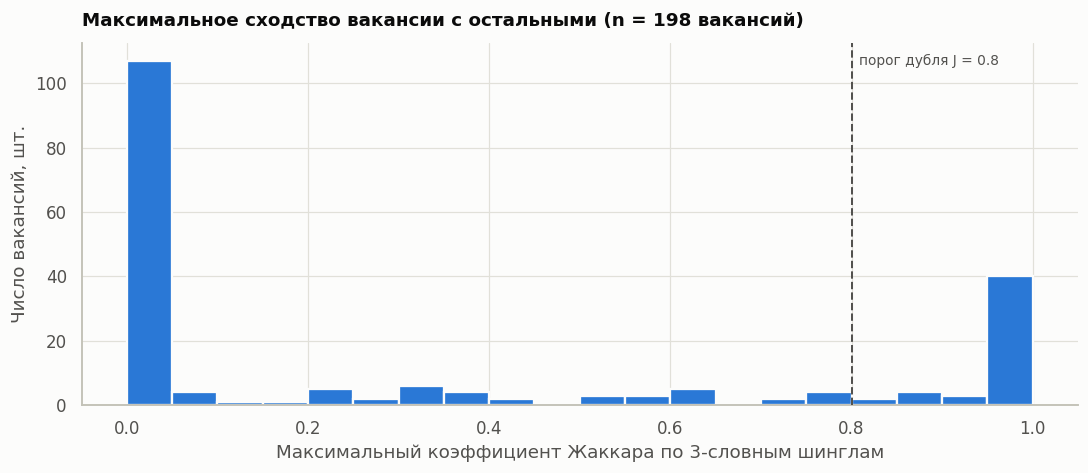

In [21]:
#@title Задание со звёздочкой C. Дедупликация вакансий: шинглы + Жаккар { display-mode: "form" }
SHINGLE_K = 3                 # длина шингла в словах
JACCARD_THRESHOLD = 0.8       # порог «почти дубля»; чувствительность к нему проверяем ниже
THRESHOLDS = [0.5, 0.6, 0.7, 0.8, 0.9, 1.0]


def shingles(text, k=SHINGLE_K):
    """Множество k-словных шинглов нормализованного текста."""
    words = re.findall(r"\w+", str(text or "").lower())
    if len(words) < k:
        return {" ".join(words)} if words else set()
    return {" ".join(words[i:i + k]) for i in range(len(words) - k + 1)}


def jaccard(a, b):
    """|A ∩ B| / |A ∪ B|: 1 — тексты совпадают, 0 — общих шинглов нет."""
    return len(a & b) / len(a | b) if a and b else 0.0


dedup = df_api.reset_index(drop=True)
docs = (dedup[["job_name", "duty", "requirements"]].fillna("")
        .agg(" ".join, axis=1).map(shingles).tolist())
n_docs = len(docs)
sim = pd.DataFrame([(i, j, jaccard(docs[i], docs[j]))
                    for i in range(n_docs) for j in range(i + 1, n_docs)],
                   columns=["i", "j", "jaccard"])
print(f"Вакансий: {n_docs}, сравнено пар: {len(sim):,}".replace(",", " "))


def cluster_ids(threshold):
    """Union-find: вакансии, связанные цепочкой пар с J ≥ порога, — один кластер."""
    parent = list(range(n_docs))

    def find(x):
        while parent[x] != x:
            parent[x] = parent[parent[x]]
            x = parent[x]
        return x

    for i, j in sim.loc[sim["jaccard"] >= threshold, ["i", "j"]].itertuples(index=False):
        parent[find(i)] = find(j)
    return pd.Series([find(i) for i in range(n_docs)])


median_all, mean_all = dedup["salary_mid"].median(), dedup["salary_mid"].mean()
rows = []
for t in THRESHOLDS:
    clusters = cluster_ids(t)
    unique = dedup.loc[~clusters.duplicated()]          # одна вакансия на кластер
    rows.append({"порог J": t, "вакансий после": clusters.nunique(),
                 "доля дублей, %": round((1 - clusters.nunique() / n_docs) * 100, 1),
                 "медиана после, руб.": unique["salary_mid"].median(),
                 "среднее после, руб.": round(unique["salary_mid"].mean())})
sensitivity = pd.DataFrame(rows)
sensitivity["сдвиг медианы, руб."] = sensitivity["медиана после, руб."] - median_all
sensitivity["сдвиг среднего, руб."] = sensitivity["среднее после, руб."] - round(mean_all)
print(f"До дедупликации: медиана {median_all:,.0f} руб., среднее {mean_all:,.0f} руб."
      .replace(",", " "))
display(sensitivity)

# Где сидят дубли: структура выборки по ролям до и после чистки при рабочем пороге
clusters = cluster_ids(JACCARD_THRESHOLD)
unique = dedup.loc[~clusters.duplicated()]
by_role = pd.DataFrame({"до, шт.": dedup["role"].value_counts(),
                        "после, шт.": unique["role"].value_counts()}).fillna(0).astype(int)
by_role["доля дублей, %"] = ((1 - by_role["после, шт."] / by_role["до, шт."]) * 100).round(1)
by_role["доля в выборке до, %"] = (by_role["до, шт."] / n_docs * 100).round(1)
by_role["доля в выборке после, %"] = (by_role["после, шт."] / len(unique) * 100).round(1)
by_role["медиана до, руб."] = dedup.groupby("role")["salary_mid"].median()
by_role["медиана после, руб."] = unique.groupby("role")["salary_mid"].median()
display(by_role.sort_values("до, шт.", ascending=False))

# Примеры найденных дублей при рабочем пороге — без персональных данных
pairs = sim[sim["jaccard"] >= JACCARD_THRESHOLD].sort_values("jaccard", ascending=False)
pairs = pairs.assign(
    job_a=dedup.loc[pairs["i"], "job_name"].values,
    job_b=dedup.loc[pairs["j"], "job_name"].values,
    region_a=dedup.loc[pairs["i"], "region"].values,
    region_b=dedup.loc[pairs["j"], "region"].values,
    same_employer=(dedup.loc[pairs["i"], "employer_id"].values
                   == dedup.loc[pairs["j"], "employer_id"].values))
print(f"Пар-дублей при J ≥ {JACCARD_THRESHOLD}: {len(pairs)}, "
      f"из них от одного работодателя: {pairs['same_employer'].mean():.0%}")
display(pairs.head(8)[["jaccard", "job_a", "region_a", "job_b", "region_b", "same_employer"]]
        .round(3))

# Распределение максимального сходства каждой вакансии с остальными
max_sim = pd.concat([sim.groupby("i")["jaccard"].max(),
                     sim.groupby("j")["jaccard"].max()]).groupby(level=0).max()
fig, ax = plt.subplots(figsize=(10, 4.4))
sns.histplot(x=max_sim, bins=np.arange(0, 1.05, 0.05), color=ACCENT, edgecolor=SURFACE,
             linewidth=1.5, alpha=1, ax=ax)
ref_line(ax, JACCARD_THRESHOLD, f"порог дубля J = {JACCARD_THRESHOLD}")
ax.set(title=f"Максимальное сходство вакансии с остальными (n = {len(max_sim)} вакансий)",
       xlabel="Максимальный коэффициент Жаккара по 3-словным шинглам",
       ylabel="Число вакансий, шт.")
plt.tight_layout()
plt.show()

**Результат задания C.**

* **Метод.** Текст вакансии (название, обязанности, требования) разбит на 3-словные шинглы. Для всех 19 503 пар посчитан коэффициент Жаккара, пары с J ≥ 0,8 объединены в кластеры через union-find, чтобы цепочки дублей тоже склеивались.
* **Распределение бимодальное.** У большинства вакансий максимальное сходство меньше 0,1, затем почти пусто, затем пик около 1,0. Рабочий порог 0,8 лежит в этой «долине», поэтому результат слабо зависит от выбора порога: при J от 0,6 до 0,9 доля дублей составляет 18,7–23,2 %.
* **Доля дублей** при J ≥ 0,8 — **20,2 %**: из 198 вакансий уникальных 158. Точных копий (J = 1,0) всего 1 %, остальное — та же вакансия с другим городом или названием. Например, «Менеджер по продажам» и «Специалист по интернет-торговле» одного работодателя совпадают по тексту на 97 %.
* **Проверка качества.** Все 506 найденных пар принадлежат одному работодателю (сверка по обезличенному `employer_id`): метод не склеивает вакансии разных компаний.
* **Влияние на зарплаты.** Общая медиана устойчива: 80 000 руб. до и после чистки при любом пороге. Среднее смещается на 2,7–4,0 тыс. руб. (при J = 0,8 — с 90 355 до 93 408 руб.). Сильнее дубли искажают структуру выборки: среди складских вакансий 43,8 % дублей, и массовый найм раздувает их долю с 28,5 до 40,4 %. Медианы внутри ролей тоже сдвигаются: склад — с 82 800 до 86 250 руб., продажи и управление — с 70 000 до 77 500 руб.
* **Вывод.** Для общей медианы дедупликация некритична, но метрики по ролям и регионам без неё смещены к массовым вакансиям. Дедупликацию стоит встроить в основной пайплайн перед расчётом метрик.